<a href="https://colab.research.google.com/github/JohnCrabs/Atmosphere_Covid_Neural_Network_ACNN/blob/master/VocSignal2Image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install numpy pandas matplotlib pillow scipy openpyxl PyWavelets

# Mount Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Import Libraries

In [3]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set up parameters

In [4]:
DATA_DIR_PATH = "/content/drive/MyDrive/Data"
DATA_PATH = "/content/drive/MyDrive/Data/1D_intensity.xlsx"
JSON_PATH = "/content/drive/MyDrive/Data/1D_intensity.json"
JSON_IONISM_PATH = "/content/drive/MyDrive/Data/1D_intensity_ionism.json"
LABELS_PATH = "/content/drive/MyDrive/Data/labels_bin.csv"
OUTPUT_DIR = "/content/drive/MyDrive/Data/output"

GEN_CORE_DATA = (not os.path.exists(JSON_PATH) and not os.path.exists(JSON_IONISM_PATH))

# Plot the signal (Visualization)

In [5]:
def plot_intensity_and_smoothed_signals(data_dict, base_output_dir, window_size=50):
    """
    Generates and saves plots for original and normalized smoothed intensity signals.

    Args:
        data_dict (dict): A dictionary where keys are signal names and values are dicts
                          containing 'mass' and 'intensity' lists.
        base_output_dir (str): The base directory to save the output plots.
        window_size (int): The window size for the moving average smoothing filter.
    """
    output_base_dir = os.path.join(base_output_dir, 'output')
    os.makedirs(output_base_dir, exist_ok=True)

    print(f"Generating plots for {len(data_dict)} signals...")

    for json_key, data in data_dict.items():
        mass = data['mass']
        intensity = data['intensity']

        # Determine common y-axis limits for original and un-normalized smoothed plot
        min_y = np.min(intensity)
        max_y = np.max(intensity)

        # Create output directory for the current key
        current_output_dir = os.path.join(output_base_dir, json_key)
        os.makedirs(current_output_dir, exist_ok=True)

        # Plot 1: Original Intensity Signal
        plt.figure(figsize=(10, 6))
        plt.plot(mass, intensity)
        plt.title(f'Original Intensity Signal for {json_key}')
        plt.xlabel('Mass')
        plt.ylabel('Intensity')
        plt.grid(True)
        plt.ylim(min_y, max_y) # Set consistent y-axis limits
        plt.tight_layout()
        original_plot_path = os.path.join(current_output_dir, f'{json_key}_intensity.jpg')
        plt.savefig(original_plot_path)
        plt.close() # Close the plot to free up memory

        # Apply a simple moving average for smoothing
        # 'valid' mode returns output of length max(M, N) - min(M, N) + 1.
        # The smoothed signal will be shorter than the original.
        if len(intensity) >= window_size:
            smoothed_intensity = np.convolve(intensity, np.ones(window_size)/window_size, mode='valid')
            # Create a common mass axis for smoothed data
            smoothed_mass = mass[window_size - 1:]
        else:
            smoothed_intensity = intensity
            smoothed_mass = mass
            print(f"Warning: Signal {json_key} is too short ({len(intensity)} points) for window_size {window_size}. No smoothing applied.")

        # Normalize the smoothed intensity to [-1, 1]
        min_smoothed = np.min(smoothed_intensity)
        max_smoothed = np.max(smoothed_intensity)

        if (max_smoothed - min_smoothed) == 0:
            normalized_smoothed_intensity = np.zeros_like(smoothed_intensity)
        else:
            normalized_smoothed_intensity = 2 * (smoothed_intensity - min_smoothed) / (max_smoothed - min_smoothed) - 1

        # Plot 2: Normalized Smoothed Intensity Signal
        plt.figure(figsize=(10, 6))
        plt.plot(smoothed_mass, normalized_smoothed_intensity, color='red')
        plt.title(f'Normalized Smoothed Intensity Signal for {json_key} (Window Size: {window_size})')
        plt.xlabel('Mass')
        plt.ylabel('Normalized Intensity ([-1, 1])')
        plt.grid(True)
        plt.ylim(-1, 1) # Set y-axis to [-1, 1] for normalized data
        plt.tight_layout()
        normalized_smoothed_plot_path = os.path.join(current_output_dir, f'{json_key}_normalized_smoothed_intensity.jpg')
        plt.savefig(normalized_smoothed_plot_path)
        plt.close() # Close the plot to free up memory

    print(f"All plots (original and normalized smoothed) have been generated and saved to subdirectories under {output_base_dir}/")


# Generate core data sorted by a column (this column is considered the X-axis)
In this stage two JSON files will be created as well.

In [6]:
def generate_core_data(data_path, data_dir_path, sort_by="Mass"):
  df = pd.read_excel(DATA_PATH)
  # display(df.head())

  df_sorted = df.sort_values(by=sort_by, ascending=True)
  # display(df_sorted.head())

  data_dict = {}
  mass_values = df_sorted['Mass'].tolist()

  for col_name in df_sorted.columns:
      if col_name != 'Mass':
          data_dict[col_name] = {
              "mass": mass_values,
              "intensity": df_sorted[col_name].tolist()
          }

  # Display the first few items to show the structure
  # Note: The full dictionary can be very large depending on your data.
  # We'll display a small subset to verify the structure.
  print("First 3 entries of the generated dictionary:")
  for i, (key, value) in enumerate(data_dict.items()):
      if i >= 3:
          break
      print(f"'{key}': {{'mass': [mass_value1, ...], 'intensity': [intensity_value1, ...]}}")
      print(f"  Example mass values (first 5): {value['mass'][:5]}")
      print(f"  Example intensity values (first 5): {value['intensity'][:5]}")
      print("...")

  with open(JSON_PATH, 'w') as f:
      json.dump(data_dict, f, indent=4)

  print(f"Dictionary successfully exported to {JSON_PATH}")

  # Define the path for the new JSON file
  IONISM_JSON_PATH = os.path.join(DATA_DIR_PATH, "1D_intensity_ionism.json")

  # Initialize the new dictionary structure
  ionism_data_dict = {}

  # Iterate through the original data_dict
  for column_id, data in data_dict.items():
      mass_values = data['mass']
      intensity_values = data['intensity']

      # Initialize structure for the current column_id
      ionism_data_dict[column_id] = {
          "negative_ionism": {
              "mass": [],
              "intensity": []
          },
          "positive_ionism": {
              "mass": [],
              "intensity": []
          }
      }

      # Iterate through mass and intensity to split them
      for mass, intensity in zip(mass_values, intensity_values):
          if mass < 0:
              ionism_data_dict[column_id]["negative_ionism"]["mass"].append(mass)
              ionism_data_dict[column_id]["negative_ionism"]["intensity"].append(intensity)
          elif mass > 0:
              ionism_data_dict[column_id]["positive_ionism"]["mass"].append(mass)
              ionism_data_dict[column_id]["positive_ionism"]["intensity"].append(intensity)
          # Masses equal to 0 will be ignored as per the negative/positive split request

  # Save the new dictionary to a JSON file
  with open(IONISM_JSON_PATH, 'w') as f:
      json.dump(ionism_data_dict, f, indent=4)

  print(f"New ionism data successfully exported to {IONISM_JSON_PATH}")

  # Display the structure of the first few entries for verification
  print("\nFirst 3 entries of the generated ionism dictionary:")
  for i, (key, value) in enumerate(ionism_data_dict.items()):
      if i >= 3:
          break
      print(f"'{key}':{{")
      print(f"  'negative_ionism': {{'mass': {value['negative_ionism']['mass'][:5]}, 'intensity': {value['negative_ionism']['intensity'][:5]}}}")
      print(f"  'positive_ionism': {{'mass': {value['positive_ionism']['mass'][:5]}, 'intensity': {value['positive_ionism']['intensity'][:5]}}}")
      print(f"}}")
      print("...")

  # Call the function to generate the plots
  # DATA_DIR_PATH is available from previous cells
  # data_dict is available from previous cells
  plot_intensity_and_smoothed_signals(data_dict, DATA_DIR_PATH, window_size=64)



In [7]:
if GEN_CORE_DATA:
  generate_core_data(DATA_PATH, DATA_DIR_PATH)

# Load JSON Files

In [8]:
df_intensity = pd.read_json(JSON_PATH)
df_intensity_ionism = pd.read_json(JSON_IONISM_PATH)

In [9]:
df_intensity

,H72,H73,H74,H75,H76,H77,H78,H79,H80,H81,...,VOCORDER_KI35,VOCORDER_KI36,VOCORDER_KI37,VOCORDER_KI4,VOCORDER_KI5,VOCORDER_KI6,VOCORDER_KI7,VOCORDER_KI8,VOCORDER_LU1,VOCORDER_LU2
mass,"[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...",...,"[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -...","[-482.5289, -371.0629, -330.0422, -319.2465, -..."
intensity,"[11141888, 50198916, 75835327, 24859322, 31483...","[9695347, 51221531, 72852197, 24311377, 822430...","[5639265, 25056731, 31375418, 20524137, 353355...","[6238260, 79649214, 90262981, 27310829, 396657...","[8832374, 79203344, 83251159, 24394454, 536346...","[14805873, 49832688, 50240114, 20628932, 40901...","[16547603, 53294068, 45246105, 17773124, 49506...","[19214438, 59747431, 64372006, 21906059, 10776...","[18374488, 48747792, 65018335, 32402966, 10579...","[8646064, 69949875, 84496109, 19541960, 757979...",...,"[6994889, 41213154, 70216501, 25269639, 447139...","[21676348, 34180805, 62314100, 26142033, 13329...","[11119432, 36457124, 70459635, 32193729, 24143...","[31868253, 39016254, 50360677, 20379989, 26108...","[25186928, 37058876, 49303182, 9189217, 242865...","[7299124, 44055137, 66183665, 10615252, 605752...","[10791161, 40395495, 45668558, 8714924, 237447...","[29987520, 68434609, 57478594, 14956239, 35633...","[20541822, 38716029, 97038183, 29757803, 23117...","[17463480, 39163698, 83385214, 33449064, 33643..."


In [10]:
df_intensity_ionism

,H72,H73,H74,H75,H76,H77,H78,H79,H80,H81,...,VOCORDER_KI35,VOCORDER_KI36,VOCORDER_KI37,VOCORDER_KI4,VOCORDER_KI5,VOCORDER_KI6,VOCORDER_KI7,VOCORDER_KI8,VOCORDER_LU1,VOCORDER_LU2
negative_ionism,"{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...",...,"{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31...","{'mass': [-482.5289, -371.0629, -330.0422, -31..."
positive_ionism,"{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...",...,"{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ...","{'mass': [51.0224, 53.0024, 53.0388, 55.0181, ..."


# 1D Signal to 2D images

### 1. Reshape Method

**Concept:** The reshape method is the simplest form of 1D to 2D transformation. It treats the 1D signal (intensity array) as a continuous sequence of pixel values and arranges them into a 2D grid of a specified `image_width` and `image_height`.

**Mathematical Workflow:**
1.  **Input Signal:** A 1D intensity array, `I = [i_1, i_2, ..., i_N]`, where `N` is the length of the signal.
2.  **Target Image Dimensions:** `image_width` (W) and `image_height` (H). The total number of pixels in the target image is `P = W * H`.
3.  **Normalization:** The intensity values are typically normalized to a specific range (e.g., 0-255 for an 8-bit grayscale image). This is done using min-max scaling:
    `I_normalized[k] = 255 * (I[k] - min(I)) / (max(I) - min(I))`
    If `max(I) - min(I)` is zero, all `I_normalized[k]` are set to 0.
4.  **Length Adjustment (Padding/Truncation):**
    *   **If `N < P` (signal is shorter than target pixels):** The `I_normalized` array is padded with zeros (or a constant value) until its length reaches `P`. This extends the signal to fit the target image size.
        `I_padded = [I_normalized[1], ..., I_normalized[N], 0, ..., 0]` (total length P)
    *   **If `N > P` (signal is longer than target pixels):** The `I_normalized` array is truncated to `P` elements. This discards the latter part of the signal.
        `I_truncated = [I_normalized[1], ..., I_normalized[P]]` (total length P)
    *   **If `N = P` (signal matches target pixels):** No adjustment is needed.
5.  **Reshaping:** The adjusted 1D array (either `I_padded`, `I_truncated`, or `I_normalized` directly) of length `P` is then reshaped into a `H x W` 2D matrix.
    `Image_Matrix[row, col] = Adjusted_I[row * W + col]`
    The elements are filled row by row, from left to right.
6.  **Output:** A 2D grayscale image (H x W pixels) where each pixel value corresponds to a normalized intensity value from the original signal.

**Characteristics:**
*   **Simplicity:** Very straightforward to implement.
*   **Lossy/Redundant:** Can involve truncation (loss of information) or padding (introduction of artificial data).
*   **No Feature Extraction:** Does not extract any inherent features or patterns from the signal; it's purely a structural rearrangement.
*   **Direct Mapping:** Each pixel directly corresponds to an intensity value (or a padded zero) from the original signal, albeit repositioned.

### 2. Spectrogram Method (Short-Time Fourier Transform - STFT)

**Concept:** A spectrogram is a visual representation of the spectrum of frequencies of a signal as it varies with time. It's generated using the Short-Time Fourier Transform (STFT), which breaks down a longer time signal into shorter segments of equal length and then computes the Fourier transform for each segment.

**Mathematical Workflow:**
1.  **Input Signal:** A 1D intensity array, `x[n]`, where `n` is the discrete time index.
2.  **Windowing:** The signal `x[n]` is divided into overlapping segments. Each segment is multiplied by a window function `w[n]` (e.g., Hann, Hamming window) to reduce spectral leakage.
    `x_m[n] = x[n] * w[n - mR]`
    where `m` is the segment index, `R` is the hop size (step between successive windows).
3.  **Discrete Fourier Transform (DFT):** For each windowed segment `x_m[n]`, the Discrete Fourier Transform is computed to obtain its frequency spectrum.
    `X_m[k] = \sum_{n=0}^{N-1} x_m[n] * e^{-j (2 \pi k n / N)}`
    where `N` is the window length, and `k` represents the frequency bin.
4.  **Magnitude Spectrogram:** The magnitude (absolute value) of the STFT result is typically used to represent the energy at each frequency over time. The squared magnitude is often used for power spectrograms.
    `S[m, k] = |X_m[k]|`
5.  **Image Formation:** The `S[m, k]` matrix forms the basis of the 2D image. Time (segment index `m`) is typically mapped to the x-axis, and frequency (frequency bin `k`) is mapped to the y-axis.
6.  **Normalization and Resizing:** The values in the spectrogram matrix are normalized to a specific range (e.g., 0-255 for grayscale) and then resized using interpolation (e.g., bilinear) to fit the desired `image_width` and `image_height`.

**Characteristics:**
*   **Time-Frequency Analysis:** Provides insight into how the frequency components of a signal evolve over time.
*   **Parameter Dependent:** The appearance of the spectrogram depends heavily on parameters like window size, overlap, and type of window function.
*   **Information Rich:** Captures more complex patterns than simple reshaping, making it suitable for analyzing signals with varying spectral content.
*   **Lossy:** Due to windowing and fixed image size, some information might be lost or approximated during the transformation.

### 3. Statistical Features Method

**Concept:** This method transforms a 1D signal into a 2D image by summarizing segments of the signal with statistical measures. Each row of the resulting image represents a statistical feature (e.g., mean) of a corresponding segment of the original signal. This approach aims to capture local characteristics of the signal.

**Mathematical Workflow:**
1.  **Input Signal:** A 1D intensity array, `I = [i_1, i_2, ..., i_N]`, where `N` is the length of the signal.
2.  **Target Image Dimensions:** `image_width` (W) and `image_height` (H).
3.  **Segmentation:** The input signal `I` is divided into `H` (equal or approximately equal) segments. If the signal length `N` is not perfectly divisible by `H`, the segments might have slightly different lengths. If `N < H`, the signal is often padded with zeros to reach at least length `H` before segmentation.
    `Segment_j = [i_k, i_{k+1}, ..., i_l]` for `j = 1, ..., H`.
4.  **Feature Extraction:** For each segment `Segment_j`, a chosen statistical feature (e.g., mean, median, standard deviation) is calculated. In our implementation, we used the mean.
    `Feature_j = mean(Segment_j)`
    This results in a 1D array of features: `F = [Feature_1, Feature_2, ..., Feature_H]`.
5.  **Normalization:** The calculated features `F` are normalized to a specific range (e.g., 0-255 for an 8-bit grayscale image).
    `F_normalized[j] = 255 * (F[j] - min(F)) / (max(F) - min(F))`
    If `max(F) - min(F)` is zero, all `F_normalized[j]` are set to 0.
6.  **Image Formation:** A 2D image is constructed where each row is filled with the same normalized feature value, repeated `W` times. That is, for each `j` from 1 to `H`:
    `Image_Matrix[j, :] = F_normalized[j]` (repeated `W` times)

**Characteristics:**
*   **Feature-Based:** Focuses on extracting interpretable statistical properties from the signal.
*   **Dimensionality Reduction:** Summarizes potentially long signal segments into single values, reducing data dimensionality.
*   **Local Information:** Captures local trends and characteristics within different parts of the signal.
*   **Lossy:** A significant amount of information from the original signal within each segment is lost, as only a single statistical measure represents it.

### 4. Discrete Wavelet Transform (DWT)

**Concept:** The Discrete Wavelet Transform (DWT) is a signal processing technique that decomposes a signal into different frequency components (sub-bands) at different resolutions. It provides a localized representation of the signal in both time and frequency, making it suitable for analyzing signals with transient features or non-stationary characteristics. Unlike the STFT, which uses fixed window sizes, DWT uses variable-sized windows, providing better temporal resolution for high frequencies and better frequency resolution for low frequencies.

**Mathematical Workflow (Multiresolution Analysis - Mallat Algorithm):**
1.  **Input Signal:** A 1D intensity array, `X = [x_0, x_1, ..., x_{N-1}]`, where `N` is the length of the signal.
2.  **Decomposition Filters:** The DWT relies on a pair of filters:
    *   **Low-pass filter (L):** `h[n]` - averages the signal, capturing low-frequency components (approximations).
    *   **High-pass filter (H):** `g[n]` - captures high-frequency components (details).
    These filters are related (quadrature mirror filters).
3.  **Convolution and Downsampling (Level 1):**
    The signal `X` is convolved with both the low-pass filter `h` and the high-pass filter `g`.
    *   **Approximation Coefficients (cA1):** Result from convolution with `h` and then downsampled by 2 (keeping every second sample). These represent the coarse features of the signal.
        `cA1[k] = \sum_{n} X[n] \cdot h[2k - n]`
    *   **Detail Coefficients (cD1):** Result from convolution with `g` and then downsampled by 2. These capture the high-frequency details or rapid changes in the signal.
        `cD1[k] = \sum_{n} X[n] \cdot g[2k - n]`
    The lengths of `cA1` and `cD1` are approximately `N/2`.
4.  **Iterative Decomposition (Multilevel):** For subsequent levels, the approximation coefficients from the previous level (`cA1`, `cA2`, etc.) are further decomposed using the same filter pair. This process is repeated for a desired number of levels.
    `cA_{j+1}, cD_{j+1} = DWT(cA_j)`
    Where `j` is the decomposition level.

5.  **Image Formation:**
    To form a 2D image from the DWT coefficients, various strategies can be employed. A common approach involves:
    *   **Concatenation:** Concatenating the approximation and detail coefficients (`cA` and `cD`) from one or more levels into a single 1D feature vector.
        `Feature_Vector = [cA_L, cD_L, ..., cD_1]` (where `L` is the highest decomposition level)
    *   **Padding/Truncation and Reshaping:** Similar to the reshape method, this `Feature_Vector` is then padded or truncated to fit the `image_width * image_height` target size.
    *   **Normalization:** The values in the reshaped matrix are normalized to a range (e.g., 0-255) to form the grayscale image.

**Characteristics:**
*   **Multiresolution Analysis:** Provides analysis at different scales, capturing both broad trends and fine details.
*   **Time-Frequency Localization:** Offers better localization in both time (for high frequencies) and frequency (for low frequencies) compared to STFT.
*   **Energy Compaction:** Often concentrates signal energy into a few coefficients, useful for compression and denoising.
*   **Choice of Wavelet:** The performance and appearance of the transform depend on the chosen wavelet family (e.g., Haar, Daubechies 'dbX', Symlets 'symX').
*   **Computational Efficiency:** Can be more computationally efficient for certain tasks than continuous transforms.

### 5. Line Plot Method

**Concept:** The line plot method directly visualizes the 1D signal as a graph of intensity versus mass. The resulting image is essentially a rendered plot of the signal, capturing its shape and trends in a conventional graphical format.

**Mathematical Workflow:**
1.  **Input Signal:** A 1D intensity array `I = [i_1, i_2, ..., i_N]` and a corresponding 1D mass array `M = [m_1, m_2, ..., m_N]`.
2.  **Plot Generation:** A standard 2D line plot is generated where:
    *   The x-axis represents the mass values (`M`).
    *   The y-axis represents the intensity values (`I`).
    Each point `(m_k, i_k)` is plotted, and consecutive points are connected by lines.
3.  **Visualization Parameters:** The appearance of the plot (e.g., line color, thickness, grid, titles, labels) is configured. Key parameters often include:
    *   `figsize`: The size of the figure in inches.
    *   `dpi`: Dots per inch, determining the resolution of the image.
    *   `title`, `xlabel`, `ylabel`: Descriptive texts for the plot.
    *   `grid`: Inclusion of a background grid.
    *   `axis('off')`: Often used to remove axis labels and ticks when the plot is intended purely as an image.
4.  **Image Rendering and Saving:** The generated plot is rendered into a pixel-based image format (e.g., PNG, JPEG). The plot area is adjusted to fit snugly within the specified output dimensions, often using `tight_layout` and `bbox_inches='tight', pad_inches=0` to minimize whitespace around the plot itself.

**Characteristics:**
*   **Direct Representation:** Provides a direct and easily interpretable visual representation of the original signal.
*   **Human Readable:** Highly intuitive for human observers to understand signal trends.
*   **Information Preservation:** While rendering to a fixed-size image can introduce some loss of detail (especially for very high-resolution signals mapped to small images), it preserves the relative relationships and overall shape of the signal.
*   **Not a Feature Extraction Method:** Unlike other methods that transform data into new feature spaces (e.g., frequency, statistical), the line plot is primarily a visualization rather than a feature engineering technique in the traditional sense. Its 'image' is a direct visual translation of the raw data.
*   **Fixed Image Size:** The plot is scaled and rendered to fit the specified `image_width` and `image_height`.

### 7. Continuous Wavelet Transform (CWT)

**Concept:** The Continuous Wavelet Transform (CWT) is a powerful tool for time-frequency analysis, similar to STFT but with a key difference: it uses wavelets, which are small oscillations localized in time, rather than sinusoids. This allows CWT to analyze different frequency components of a signal with varying time resolutions – higher frequencies with better time resolution, and lower frequencies with better frequency resolution. It provides a more detailed and flexible decomposition of a signal than the Fourier Transform, especially for non-stationary signals.

**Mathematical Workflow:**
1.  **Input Signal:** A 1D intensity array (time series), `x(t)`.
2.  **Mother Wavelet:** Choose a mother wavelet function, `\psi(t)`. Common choices include Morlet, Mexican Hat (mexh), Gaussian (gaus), and Complex Gaussian (cgau) wavelets. The mother wavelet must satisfy certain conditions, such as having zero mean and being localized in both time and frequency.
3.  **Scaling and Translation:** The mother wavelet is scaled (stretched or compressed) and translated (shifted in time) to create a family of wavelets `\psi_{a,b}(t)`:
    `\psi_{a,b}(t) = \frac{1}{\sqrt{a}} \psi\left(\frac{t-b}{a}\right)`
    where:
    *   `a` is the scaling parameter (dilation), `a > 0`. Larger `a` corresponds to a stretched wavelet, capturing lower frequencies. Smaller `a` corresponds to a compressed wavelet, capturing higher frequencies.
    *   `b` is the translation parameter (location), which shifts the wavelet along the time axis.
    *   `1/\sqrt{a}` is a normalization factor to ensure that the energy of the wavelet remains constant across scales.
4.  **CWT Calculation:** The CWT of the signal `x(t)` with respect to the wavelet `\psi_{a,b}(t)` is defined as the convolution of `x(t)` with the complex conjugate of the scaled and translated wavelet:
    `C(a,b) = \int_{-\infty}^{\infty} x(t) \psi^*_{a,b}(t) dt`
    This integral calculates the correlation between the signal and the wavelet at various scales (`a`) and positions (`b`). The result `C(a,b)` is a 2D matrix of wavelet coefficients, where `a` often corresponds to the y-axis (scale/frequency) and `b` to the x-axis (time).
5.  **Image Formation:** The magnitude of the wavelet coefficients `|C(a,b)|` forms the basis of the 2D image. The scales (or corresponding frequencies) are typically mapped to the y-axis and time to the x-axis. This creates a scalogram (or spectrogram-like) representation.
6.  **Normalization and Resizing:** The values in the `|C(a,b)|` matrix are normalized to a specific range (e.g., 0-255 for grayscale) and then resized using interpolation to fit the desired `image_width` and `image_height`.

**Characteristics:**
*   **Multi-Resolution Analysis:** Provides an excellent balance of time and frequency resolution, adapting to the signal's characteristics. Good for analyzing transients and non-stationary signals.
*   **Flexibility with Wavelets:** The choice of mother wavelet allows tailoring the analysis to specific signal features (e.g., detecting sharp changes with a 'mexh' wavelet or oscillatory components with 'morl').
*   **Redundant Information:** The CWT produces a highly redundant representation of the signal, which can be an advantage for analysis but a disadvantage for data compression.
*   **Computational Cost:** Can be more computationally intensive than DWT due to the continuous nature of scaling and translation.

### 6. Recurrence Plot Method

**Concept:** A recurrence plot (RP) is an advanced visualization tool used to investigate the recurrent behavior of dynamical systems. It displays all times when the state of a dynamical system is approximately the same, i.e., when its trajectory in phase space returns to a neighborhood it has visited before. For 1D time series, it helps visualize periodicities, non-stationarities, and chaotic behavior.

**Mathematical Workflow:**
1.  **Input Signal:** A 1D intensity array (time series), `x = [x_1, x_2, ..., x_N]`.
2.  **Phase Space Reconstruction (Embedding):** The first step is to reconstruct the phase space of the system from the scalar time series using the method of delays. This creates a sequence of state vectors `v_i`:
    `v_i = (x_i, x_{i+\tau}, x_{i+2\tau}, ..., x_{i+(m-1)\tau})`
    where:
    *   `m` is the embedding dimension (number of components in each state vector).
    *   `\tau` is the time delay.
    *   `i` ranges from `1` to `N - (m-1)\tau`.
    Each `v_i` represents a state of the system at time `i` in an `m`-dimensional space.
3.  **Recurrence Matrix Calculation:** The core of the recurrence plot is the recurrence matrix `R`, an `NxN` (or `(N-(m-1)\tau)x(N-(m-1)\tau)`) binary matrix. An element `R_{i,j}` is 1 if the state at time `i` (`v_i`) is "close" to the state at time `j` (`v_j`), and 0 otherwise.
    `R_{i,j} = \Theta(\epsilon - ||v_i - v_j||)`
    where:
    *   `\Theta` is the Heaviside function (`\Theta(k) = 1` if `k \ge 0`, `0` otherwise).
    *   `\epsilon` is a predefined threshold distance (radius).
    *   `||.||` denotes a norm (e.g., Euclidean or Manhattan distance). We consider states `v_i` and `v_j` to be recurrent if their distance is less than or equal to `\epsilon`.
    *   `percentage` parameter (as used in `pyts`): Instead of a fixed `\epsilon`, one can define `\epsilon` such that a certain `percentage` of points are recurrent.
4.  **Image Formation:** The binary recurrence matrix `R` is directly visualized as a grayscale image. Typically, recurrent points (where `R_{i,j} = 1`) are plotted as black dots, and non-recurrent points (where `R_{i,j} = 0`) as white dots. The axes of the image represent the time indices `i` and `j`.
5.  **Normalization and Resizing:** The binary matrix (0 or 1) is scaled (e.g., to 0 and 255 for grayscale) and potentially resized using interpolation to fit the desired `image_width` and `image_height`.

**Characteristics:**
*   **Non-Linear Dynamics:** Especially useful for analyzing non-linear and chaotic systems, as well as periodic and quasi-periodic signals.
*   **Visual Patterns:** Recurring patterns in the signal appear as structures (lines, blocks, isolated points) in the recurrence plot, which can reveal underlying dynamics.
*   **No Dimensionality Reduction (in the sense of feature extraction):** The plot directly visualizes relationships in the (reconstructed) phase space rather than summarizing information into new features.
*   **Parameter Sensitivity:** The appearance of the recurrence plot is highly sensitive to the choice of embedding dimension `m`, time delay `\tau`, and threshold `\epsilon`.
*   **Computational Cost:** Can be computationally intensive for very long time series due to the `N x N` distance calculations.

In [11]:
import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import spectrogram, find_peaks, savgol_filter
from scipy.ndimage import zoom, gaussian_filter1d

try:
    import pywt
except ImportError:
    pywt = None


# ============================================================
# Optional hard-coded paths for non-CLI use
# ============================================================
DATA_PATH = "/content/drive/MyDrive/Data/1D_intensity.xlsx"
DATA_DIR_PATH = "/content/drive/MyDrive/Data/"


# ============================================================
# Utilities
# ============================================================

def ensure_dir(path):
    Path(path).mkdir(parents=True, exist_ok=True)


def minmax_to_uint8(arr):
    arr = np.asarray(arr, dtype=float)
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)

    if arr.size == 0:
        return np.zeros((1,), dtype=np.uint8)

    mn = np.min(arr)
    mx = np.max(arr)

    if mx - mn == 0:
        return np.zeros(arr.shape, dtype=np.uint8)

    out = 255.0 * (arr - mn) / (mx - mn)
    return np.clip(out, 0, 255).astype(np.uint8)


def normalize_signal(arr):
    arr = np.asarray(arr, dtype=float)
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)

    if arr.size == 0:
        return np.zeros((1,), dtype=float)

    mn = np.min(arr)
    mx = np.max(arr)

    if mx - mn == 0:
        return np.zeros_like(arr)

    return (arr - mn) / (mx - mn)


def resize_to_hw(arr2d, height=224, width=224, order=1):
    arr2d = np.asarray(arr2d, dtype=float)

    if arr2d.ndim != 2:
        raise ValueError("resize_to_hw expects a 2D array.")

    if arr2d.shape[0] == 0 or arr2d.shape[1] == 0:
        arr2d = np.zeros((2, 2), dtype=float)

    zoom_h = height / arr2d.shape[0]
    zoom_w = width / arr2d.shape[1]

    return zoom(arr2d, (zoom_h, zoom_w), order=order)


def save_grayscale(array2d, out_path):
    img = Image.fromarray(minmax_to_uint8(array2d), mode="L")
    img.save(out_path)


def save_rgb_image(img_r, img_g, img_b, out_path):
    r = minmax_to_uint8(img_r)
    g = minmax_to_uint8(img_g)
    b = minmax_to_uint8(img_b)

    rgb = np.stack([r, g, b], axis=-1)
    img = Image.fromarray(rgb, mode="RGB")
    img.save(out_path)


def safe_mass_intensity(mass, intensity):
    mass = np.asarray(mass, dtype=float)
    intensity = np.asarray(intensity, dtype=float)

    mask = np.isfinite(mass) & np.isfinite(intensity)
    return mass[mask], intensity[mask]


# ============================================================
# Input readers
# ============================================================

def read_excel(input_path):
    return pd.read_excel(input_path)


def read_json(input_path):
    with open(input_path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, dict) and "data" in obj:
        obj = obj["data"]

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        return pd.DataFrame(obj)

    raise ValueError("Unsupported JSON structure.")


def load_input(input_path):
    input_path = Path(input_path)
    suffix = input_path.suffix.lower()

    if suffix in [".xlsx", ".xls"]:
        df = read_excel(input_path)
    elif suffix == ".json":
        df = read_json(input_path)
    else:
        raise ValueError(f"Unsupported file type: {suffix}")

    if "Mass" not in df.columns:
        raise ValueError("Input must contain a 'Mass' column.")

    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=["Mass"]).copy()
    df = df.sort_values("Mass").reset_index(drop=True)
    return df


# ============================================================
# Signal analysis
# ============================================================

def basic_signal_analysis(mass, intensity):
    mass, intensity = safe_mass_intensity(mass, intensity)

    if len(intensity) == 0:
        return {
            "n_points": 0,
            "mass_min": np.nan,
            "mass_max": np.nan,
            "intensity_min": np.nan,
            "intensity_max": np.nan,
            "intensity_mean": np.nan,
            "intensity_std": np.nan,
            "num_peaks": 0,
            "top_peak_masses": "",
            "top_peak_intensities": "",
        }

    sigma = float(np.std(intensity))
    prominence = sigma if sigma > 0 else None
    peaks, _ = find_peaks(intensity, prominence=prominence)

    if len(peaks) > 0:
        top_peak_idx = peaks[np.argsort(intensity[peaks])[-5:]][::-1]
    else:
        top_peak_idx = np.array([], dtype=int)

    return {
        "n_points": int(len(intensity)),
        "mass_min": float(np.min(mass)),
        "mass_max": float(np.max(mass)),
        "intensity_min": float(np.min(intensity)),
        "intensity_max": float(np.max(intensity)),
        "intensity_mean": float(np.mean(intensity)),
        "intensity_std": float(np.std(intensity)),
        "num_peaks": int(len(peaks)),
        "top_peak_masses": ";".join([f"{mass[i]:.4f}" for i in top_peak_idx]),
        "top_peak_intensities": ";".join([f"{intensity[i]:.4f}" for i in top_peak_idx]),
    }


# ============================================================
# Splitting
# ============================================================

def split_full_negative_positive(mass, intensity):
    mass = np.asarray(mass, dtype=float)
    intensity = np.asarray(intensity, dtype=float)

    valid = np.isfinite(mass) & np.isfinite(intensity)
    full_mask = valid
    negative_mask = valid & (mass < 0)
    positive_mask = valid & (mass > 0)

    return {
        "full": (mass[full_mask], intensity[full_mask]),
        "negative": (mass[negative_mask], intensity[negative_mask]),
        "positive": (mass[positive_mask], intensity[positive_mask]),
    }


# ============================================================
# 2D transform methods
# ============================================================

def image_reshape(
    intensity,
    image_height=224,
    image_width=224,
    smooth=True,
    smooth_method="gaussian",   # "gaussian" or "savgol"
    gaussian_sigma=2.0,
    savgol_window=11,
    savgol_polyorder=2,
    normalization="robust",     # "minmax" or "robust"
    gamma=0.8,
):
    """
    Improved reshape:
    1. clean signal
    2. smooth signal
    3. robust normalize
    4. interpolate to exactly H*W values
    5. reshape

    Returns float image in [0, 255].
    """
    x = np.asarray(intensity, dtype=float)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if len(x) == 0:
        return np.zeros((image_height, image_width), dtype=float)

    # 1) smoothing
    if smooth and len(x) > 3:
        if smooth_method == "gaussian":
            x = gaussian_filter1d(x, sigma=gaussian_sigma)
        elif smooth_method == "savgol":
            win = min(savgol_window, len(x))
            if win % 2 == 0:
                win -= 1
            if win >= 3:
                poly = min(savgol_polyorder, win - 1)
                x = savgol_filter(x, window_length=win, polyorder=poly)
        else:
            raise ValueError("smooth_method must be 'gaussian' or 'savgol'")

    # 2) normalization
    if normalization == "robust":
        p1, p99 = np.percentile(x, [1, 99])
        if p99 - p1 == 0:
            x_norm = np.zeros_like(x)
        else:
            x = np.clip(x, p1, p99)
            x_norm = (x - p1) / (p99 - p1)
    elif normalization == "minmax":
        mn, mx = np.min(x), np.max(x)
        if mx - mn == 0:
            x_norm = np.zeros_like(x)
        else:
            x_norm = (x - mn) / (mx - mn)
    else:
        raise ValueError("normalization must be 'minmax' or 'robust'")

    x_norm = np.clip(x_norm, 0, 1)

    # 3) gamma correction to brighten dark regions
    if gamma is not None and gamma > 0:
        x_norm = np.power(x_norm, gamma)

    # 4) interpolate instead of padding/truncation
    target_len = image_height * image_width
    if len(x_norm) == 1:
        resampled = np.full(target_len, x_norm[0], dtype=float)
    else:
        old_idx = np.linspace(0, 1, len(x_norm))
        new_idx = np.linspace(0, 1, target_len)
        resampled = np.interp(new_idx, old_idx, x_norm)

    # 5) reshape
    return resampled.reshape(image_height, image_width) * 255.0


def image_spectrogram(intensity, image_height=224, image_width=224, nperseg=128, noverlap=64):
    x = np.asarray(intensity, dtype=float)

    if len(x) < 8:
        return np.zeros((image_height, image_width), dtype=float)

    nperseg = min(nperseg, len(x))
    noverlap = min(noverlap, max(0, nperseg - 1))

    _, _, sxx = spectrogram(
        x,
        fs=1.0,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        scaling="spectrum",
        mode="magnitude"
    )

    sxx = np.log1p(sxx)
    return resize_to_hw(sxx, image_height, image_width, order=1)


def image_statistical_features(intensity, image_height=224, image_width=224, feature="mean"):
    x = np.asarray(intensity, dtype=float)

    if len(x) == 0:
        return np.zeros((image_height, image_width), dtype=float)

    if len(x) < image_height:
        x = np.pad(x, (0, image_height - len(x)), mode="constant", constant_values=0)

    segments = np.array_split(x, image_height)
    values = []

    for seg in segments:
        if feature == "mean":
            values.append(np.mean(seg))
        elif feature == "std":
            values.append(np.std(seg))
        elif feature == "median":
            values.append(np.median(seg))
        elif feature == "max":
            values.append(np.max(seg))
        else:
            raise ValueError(f"Unsupported feature: {feature}")

    values = np.array(values, dtype=float)
    row_values = minmax_to_uint8(values).astype(float)
    return np.repeat(row_values[:, None], image_width, axis=1)


def image_dwt(intensity, image_height=224, image_width=224, wavelet="db4", level=4, smooth=True, gaussian_sigma=2.0, normalization="robust", gamma=0.8):
    if pywt is None:
        raise ImportError("PyWavelets is required for DWT.")

    x = np.asarray(intensity, dtype=float)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if len(x) < 8:
        return np.zeros((image_height, image_width), dtype=float)

    # Apply smoothing if enabled
    if smooth and len(x) > 3:
        x = gaussian_filter1d(x, sigma=gaussian_sigma)

    wavelet_obj = pywt.Wavelet(wavelet)
    max_level = pywt.dwt_max_level(len(x), wavelet_obj.dec_len)
    level = max(1, min(level, max_level if max_level >= 1 else 1))

    coeffs = pywt.wavedec(x, wavelet=wavelet, level=level)
    feat = np.concatenate([np.abs(c).ravel() for c in coeffs]) # Take absolute value and flatten

    # Normalization
    if normalization == "robust":
        p1, p99 = np.percentile(feat, [1, 99])
        if p99 - p1 == 0:
            feat_norm = np.zeros_like(feat)
        else:
            feat = np.clip(feat, p1, p99)
            feat_norm = (feat - p1) / (p99 - p1)
    elif normalization == "minmax":
        mn, mx = np.min(feat), np.max(feat)
        if mx - mn == 0:
            feat_norm = np.zeros_like(feat)
        else:
            feat_norm = (feat - mn) / (mx - mn)
    else:
        raise ValueError("normalization must be 'minmax' or 'robust'")

    feat_norm = np.clip(feat_norm, 0, 1)

    # Gamma correction
    if gamma is not None and gamma > 0:
        feat_norm = np.power(feat_norm, gamma)

    num_pixels = image_height * image_width
    if len(feat_norm) == 1:
        resampled = np.full(num_pixels, feat_norm[0], dtype=float)
    else:
        old_idx = np.linspace(0, 1, len(feat_norm))
        new_idx = np.linspace(0, 1, num_pixels)
        resampled = np.interp(new_idx, old_idx, feat_norm)

    return resampled.reshape(image_height, image_width) * 255.0


def image_lineplot(mass, intensity, image_height=224, image_width=224, dpi=100):
    mass, intensity = safe_mass_intensity(mass, intensity)

    if len(mass) == 0 or len(intensity) == 0:
        return np.zeros((image_height, image_width), dtype=float)

    fig_w = image_width / dpi
    fig_h = image_height / dpi

    fig = plt.figure(figsize=(fig_w, fig_h), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.plot(mass, intensity, linewidth=1.0)
    ax.set_axis_off()

    fig.canvas.draw()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
    buf = buf.reshape(fig.canvas.get_width_height()[::-1] + (4,))
    plt.close(fig)

    rgb = buf[:, :, :3]
    gray = np.dot(rgb[..., :3], [0.2989, 0.5870, 0.1140])

    if gray.shape != (image_height, image_width):
        gray = resize_to_hw(gray, image_height, image_width, order=1)

    return gray


def image_cwt(intensity, image_height=224, image_width=224, wavelet="morl", num_scales=64, normalization="robust", gamma=0.8):
    if pywt is None:
        raise ImportError("PyWavelets is required for CWT.")

    x = np.asarray(intensity, dtype=float)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    if len(x) < 8:
        return np.zeros((image_height, image_width), dtype=float)

    scales = np.arange(1, num_scales + 1)
    coeffs, _ = pywt.cwt(x, scales, wavelet)
    scalogram = np.log1p(np.abs(coeffs))

    # Resize before normalization to ensure the normalization is applied to the final image dimensions
    resized_scalogram = resize_to_hw(scalogram, image_height, image_width, order=1)

    # Normalization
    if normalization == "robust":
        p1, p99 = np.percentile(resized_scalogram, [1, 99])
        if p99 - p1 == 0:
            norm_resized_scalogram = np.zeros_like(resized_scalogram)
        else:
            norm_resized_scalogram = (resized_scalogram - p1) / (p99 - p1)
    elif normalization == "minmax":
        mn, mx = np.min(resized_scalogram), np.max(resized_scalogram)
        if mx - mn == 0:
            norm_resized_scalogram = np.zeros_like(resized_scalogram)
        else:
            norm_resized_scalogram = (resized_scalogram - mn) / (mx - mn)
    else:
        raise ValueError("normalization must be 'minmax' or 'robust'")

    norm_resized_scalogram = np.clip(norm_resized_scalogram, 0, 1)

    # Gamma correction
    if gamma is not None and gamma > 0:
        norm_resized_scalogram = np.power(norm_resized_scalogram, gamma)

    return norm_resized_scalogram * 255.0


def embed_time_series(x, m=3, tau=1):
    x = np.asarray(x, dtype=float)
    n = len(x)
    out_len = n - (m - 1) * tau

    if out_len <= 1:
        return None

    return np.array([[x[i + j * tau] for j in range(m)] for i in range(out_len)])


def image_recurrence_plot(intensity, image_height=224, image_width=224, m=3, tau=1, percentile=10):
    x = normalize_signal(intensity)
    v = embed_time_series(x, m=m, tau=tau)

    if v is None:
        return np.zeros((image_height, image_width), dtype=float)

    diff = v[:, None, :] - v[None, :, :]
    dist = np.sqrt(np.sum(diff ** 2, axis=2))
    eps = np.percentile(dist, percentile)
    r = (dist <= eps).astype(float)

    return resize_to_hw(r, image_height, image_width, order=0)


# ============================================================
# Method dispatch
# ============================================================

def compute_method_image(method_name, mass, intensity, image_height=224, image_width=224):
    if method_name == "reshape":
        return image_reshape(
            intensity,
            image_height=image_height,
            image_width=image_width,
            smooth=True,
            smooth_method="gaussian",
            gaussian_sigma=2.0,
            normalization="robust",
            gamma=0.8,
        )

    if method_name == "spectrogram":
        return image_spectrogram(intensity, image_height, image_width)

    if method_name == "stat_features_mean":
        return image_statistical_features(intensity, image_height, image_width, feature="mean")

    if method_name == "stat_features_std":
        return image_statistical_features(intensity, image_height, image_width, feature="std")

    if method_name == "dwt":
        return image_dwt(intensity, image_height, image_width, smooth=True, gaussian_sigma=2.0, normalization="robust", gamma=0.8)

    if method_name == "lineplot":
        return image_lineplot(mass, intensity, image_height, image_width)

    if method_name == "cwt":
        return image_cwt(intensity, image_height, image_width, normalization="robust", gamma=0.8)

    if method_name == "recurrence_plot":
        return image_recurrence_plot(intensity, image_height, image_width)

    raise ValueError(f"Unknown method: {method_name}")


def available_methods():
    methods = [
        "reshape",
        "spectrogram",
        "stat_features_mean",
        "stat_features_std",
        "lineplot",
        "recurrence_plot",
    ]

    if pywt is not None:
        methods.insert(4, "dwt")
        methods.insert(6, "cwt")

    return methods


# ============================================================
# Output generators
# ============================================================

def generate_all_grayscale_images(mass, intensity, out_dir, image_height=224, image_width=224):
    ensure_dir(out_dir)

    for method in available_methods():
        arr = compute_method_image(method, mass, intensity, image_height, image_width)
        save_grayscale(arr, Path(out_dir) / f"{method}.png")


def generate_all_rgb_images(mass_all, intensity_all, out_dir, image_height=224, image_width=224):
    ensure_dir(out_dir)

    splits = split_full_negative_positive(mass_all, intensity_all)

    neg_mass, neg_int = splits["negative"]
    pos_mass, pos_int = splits["positive"]
    full_mass, full_int = splits["full"]

    for method in available_methods():
        img_r = compute_method_image(method, neg_mass, neg_int, image_height, image_width)   # red = negative
        img_g = compute_method_image(method, pos_mass, pos_int, image_height, image_width)   # green = positive
        img_b = compute_method_image(method, full_mass, full_int, image_height, image_width) # blue = full

        save_rgb_image(img_r, img_g, img_b, Path(out_dir) / f"{method}_rgb.png")


# ============================================================
# Main pipeline
# ============================================================

def run_pipeline(input_path, output_path, height=448, width=448, max_signals=None):
    df = load_input(input_path)
    output_dir = Path(output_path)
    ensure_dir(output_dir)

    mass_all = df["Mass"].to_numpy(dtype=float)

    signal_cols = [c for c in df.columns if c != "Mass"]
    if max_signals is not None:
        signal_cols = signal_cols[:max_signals]

    summary_rows = []

    for col in signal_cols:
        intensity_all = df[col].to_numpy(dtype=float)
        sample_dir = output_dir / str(col)
        ensure_dir(sample_dir)

        splits = split_full_negative_positive(mass_all, intensity_all)

        for split_name, (mass_split, intensity_split) in splits.items():
            split_dir = sample_dir / split_name
            ensure_dir(split_dir)

            row = {
                "sample": col,
                "split": split_name,
            }
            row.update(basic_signal_analysis(mass_split, intensity_split))
            summary_rows.append(row)

            generate_all_grayscale_images(
                mass_split,
                intensity_split,
                split_dir,
                image_height=height,
                image_width=width
            )

        rgb_dir = sample_dir / "rgb"
        ensure_dir(rgb_dir)

        generate_all_rgb_images(
            mass_all,
            intensity_all,
            rgb_dir,
            image_height=height,
            image_width=width
        )

    summary_df = pd.DataFrame(summary_rows)
    summary_df.to_csv(output_dir / "analysis_summary.csv", index=False)

    print(f"Done. Processed {len(signal_cols)} signals.")
    print(f"Results saved to: {output_dir}")


def main():
    input_path = DATA_PATH
    output_path = str(Path(DATA_DIR_PATH) / "output")
    height = 448
    width = 448
    max_signals=None

    run_pipeline(
        input_path=input_path,
        output_path=output_path,
        height=height,
        width=width,
        max_signals=max_signals
    )


if __name__ == "__main__":
    main()

/tmp/ipykernel_2539/2298277851.py:82: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(minmax_to_uint8(array2d), mode="L")
/tmp/ipykernel_2539/2298277851.py:92: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb, mode="RGB")


Done. Processed 183 signals.
Results saved to: /content/drive/MyDrive/Data/output


In [12]:
import os
import pandas as pd
import numpy as np
# Removed TensorFlow imports
import torch
from torchvision import transforms
from PIL import Image # Used by torchvision.transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# For XAI
# !pip install lime
# from lime import lime_image

# --- Configuration --- #
# Defined in previous cells: LABELS_PATH, OUTPUT_DIR

IMAGE_SIZE = (128, 128) # Smaller size for faster processing and less memory usage

# --- Load Labels --- #
print(f"Loading labels from: {LABELS_PATH}")
labels_df = pd.read_csv(LABELS_PATH)
# Assuming the labels file has at least two columns: one for sample ID and one for the label
# Adjust these column names if yours are different
SAMPLE_ID_COL = labels_df.columns[0] # e.g., 'sample_id'
LABEL_COL = labels_df.columns[1]    # e.g., 'label_binary'

# Encode labels to numerical format
label_encoder = LabelEncoder()
labels_df['encoded_label'] = label_encoder.fit_transform(labels_df[LABEL_COL])
num_classes = len(label_encoder.classes_)

print(f"Loaded {len(labels_df)} labels. Number of classes: {num_classes}")
print("Label mapping:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

# --- Determine all RGB image methods --- #
ALL_RGB_IMAGE_METHODS = [
    "reshape_rgb.png",
    "spectrogram_rgb.png",
    "stat_features_mean_rgb.png",
    "stat_features_std_rgb.png",
    "dwt_rgb.png",
    "lineplot_rgb.png",
    "cwt_rgb.png",
    "recurrence_plot_rgb.png"
]
print(f"Preparing to load images for the following methods: {ALL_RGB_IMAGE_METHODS}")

# --- Preprocess Images (PyTorch style) --- #
# Define the transformation pipeline for images
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(), # Converts PIL Image to PyTorch tensor (C, H, W) and normalizes to [0, 1]
])

def load_and_preprocess_image(img_path):
    img = Image.open(img_path).convert('RGB') # Ensure image is in RGB format
    return transform(img)

# --- Load Images and Pair with Labels --- #
image_data_per_sample = [] # List to hold stacked image tensors for each sample
corresponding_labels = []
processed_sample_ids = []

print(f"Scanning for images in {OUTPUT_DIR}")
for sample_folder in os.listdir(OUTPUT_DIR):
    sample_id = sample_folder # Assuming folder name is the sample ID
    sample_label_row = labels_df[labels_df[SAMPLE_ID_COL] == sample_id]

    if not sample_label_row.empty:
        encoded_label = sample_label_row['encoded_label'].iloc[0]
        image_folder = os.path.join(OUTPUT_DIR, sample_folder, 'rgb')

        current_sample_images = []
        all_methods_found = True
        for method_filename in ALL_RGB_IMAGE_METHODS:
            target_image_path = os.path.join(image_folder, method_filename)
            if os.path.exists(target_image_path):
                current_sample_images.append(load_and_preprocess_image(target_image_path))
            else:
                # print(f"Warning: Image {target_image_path} not found for sample {sample_id}")
                all_methods_found = False
                break # Skip this sample if any image is missing

        if all_methods_found and current_sample_images:
            # Stack images for the current sample along a new axis (dimension 0)
            # Resulting tensor will have shape (num_image_methods, C, H, W)
            image_data_per_sample.append(torch.stack(current_sample_images))
            corresponding_labels.append(encoded_label)
            processed_sample_ids.append(sample_id)
    # else:
        # print(f"Warning: Label not found for sample {sample_id}")

print(f"Found and processed {len(image_data_per_sample)} samples with all {len(ALL_RGB_IMAGE_METHODS)} image types.")

# --- Stack all samples into a single PyTorch tensor --- #
# X will now have shape (num_samples, num_image_methods, C, H, W)
if image_data_per_sample:
    X = torch.stack(image_data_per_sample)
else:
    print("No samples with all RGB image types found. X will be an empty tensor.")
    # Create an empty tensor with the expected dimensions if no data
    X = torch.empty((0, len(ALL_RGB_IMAGE_METHODS), 3, IMAGE_SIZE[0], IMAGE_SIZE[1]))

# Convert labels to a PyTorch tensor (integer labels, not one-hot encoded for CrossEntropyLoss)
y = torch.tensor(corresponding_labels, dtype=torch.long)

print("Shape of image data (X):", X.shape)
print("Shape of label data (y):", y.shape)

# --- Split Data --- #
if X.shape[0] > 0:
    # train_test_split works with PyTorch tensors directly
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y.cpu().numpy() # stratify needs numpy array
    )

    print(f"Training data shape: {X_train.shape}")
    print(f"Testing data shape: {X_test.shape}")
    print(f"Training labels shape: {y_train.shape}")
    print(f"Testing labels shape: {y_test.shape}")
else:
    print("Not enough data to split. X_train, X_test, y_train, y_test will be empty tensors.")
    X_train, X_test, y_train, y_test = (
        torch.empty((0,)), torch.empty((0,)), torch.empty((0,)), torch.empty((0,))
    )

# Save label_encoder for XAI interpretation
# This can be used later to map encoded labels back to original class names
import pickle
with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

print("Label encoder saved to 'label_encoder.pkl'")

Loading labels from: /content/drive/MyDrive/Data/labels_bin.csv
Loaded 183 labels. Number of classes: 2
Label mapping: {'Diseased': np.int64(0), 'Healthy': np.int64(1)}
Preparing to load images for the following methods: ['reshape_rgb.png', 'spectrogram_rgb.png', 'stat_features_mean_rgb.png', 'stat_features_std_rgb.png', 'dwt_rgb.png', 'lineplot_rgb.png', 'cwt_rgb.png', 'recurrence_plot_rgb.png']
Scanning for images in /content/drive/MyDrive/Data/output
Found and processed 183 samples with all 8 image types.
Shape of image data (X): torch.Size([183, 8, 3, 128, 128])
Shape of label data (y): torch.Size([183])
Training data shape: torch.Size([146, 8, 3, 128, 128])
Testing data shape: torch.Size([37, 8, 3, 128, 128])
Training labels shape: torch.Size([146])
Testing labels shape: torch.Size([37])
Label encoder saved to 'label_encoder.pkl'


### Train the Multi-Input CNN Model

### Define Multi-Input CNN Architecture

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SingleImageBranch(nn.Module):
    def __init__(self):
        super(SingleImageBranch, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2) # Reduces 128x128 to 64x64
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2) # Reduces 64x64 to 32x32
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(2, 2) # Reduces 32x32 to 16x16
        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1)) # Output 1x1 feature map

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1) # Flatten to (batch_size, 128)
        return x

class MultiInputCNN(nn.Module):
    def __init__(self, num_image_methods, num_classes):
        super(MultiInputCNN, self).__init__()
        self.num_image_methods = num_image_methods

        # Create a list of CNN branches, one for each image method
        self.feature_extractors = nn.ModuleList([SingleImageBranch() for _ in range(num_image_methods)])

        # Classification head
        # Each branch outputs 128 features (from AdaptiveAvgPool2d((1,1)) with 128 channels)
        # So, concatenated features will be num_image_methods * 128
        combined_features_dim = num_image_methods * 128
        self.fc1 = nn.Linear(combined_features_dim, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        # x shape: (batch_size, num_image_methods, C, H, W)

        # Process each image type through its dedicated branch
        # Store outputs in a list
        branch_outputs = []
        for i in range(self.num_image_methods):
            # Select i-th image for all samples in the batch
            # input to branch: (batch_size, C, H, W)
            branch_output = self.feature_extractors[i](x[:, i, :, :, :])
            branch_outputs.append(branch_output)

        # Concatenate outputs from all branches along the feature dimension
        # Each branch_output is (batch_size, 128)
        # Combined will be (batch_size, num_image_methods * 128)
        combined_features = torch.cat(branch_outputs, dim=1)

        # Pass through classification head
        x = F.relu(self.fc1(combined_features))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
# num_image_methods is X.shape[1]
# num_classes is determined from label_encoder.classes_
model = MultiInputCNN(num_image_methods=X_train.shape[1], num_classes=num_classes)
print(model)


In [17]:
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# --- Hyperparameters --- #
BATCH_SIZE = 32
LEARNING_RATE = 0.001
NUM_EPOCHS = 20

# --- Device Configuration --- #
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- Move model to device --- #
model = model.to(device)

# --- Calculate Class Weights for Imbalanced Data --- #
class_counts = torch.bincount(y_train)
# The inverse of the class frequency is a common way to calculate weights
# This gives higher weights to less frequent classes
total_samples = class_counts.sum().float()
class_weights = total_samples / (len(class_counts) * class_counts.float())
class_weights = class_weights.to(device)
print(f"Calculated class weights: {class_weights}")

# --- Loss and Optimizer --- #
criterion = nn.CrossEntropyLoss(weight=class_weights) # Apply class weights here
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# --- Data Loaders --- #
# Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# --- Training Loop --- #
print("Starting training...")
for epoch in range(NUM_EPOCHS):
    model.train() # Set model to training mode
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)  # Move images to the device
        labels = labels.to(device)  # Move labels to the device

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # --- Evaluation --- #
    model.eval() # Set model to evaluation mode
    correct = 0
    total = 0
    with torch.no_grad(): # Disable gradient calculation for inference
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f'Epoch [{epoch+1}/{NUM_EPOCHS}], ')
    print(f'         Loss: {running_loss/len(train_loader):.4f}, ')
    print(f'         Test Accuracy: {100 * correct / total:.2f}%')

print("Training finished.")

# --- Save the trained model --- #
MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, 'multi_input_cnn_model.pth')
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"Model saved to {MODEL_SAVE_PATH}")

Using device: cuda
Calculated class weights: tensor([1.6222, 0.7228], device='cuda:0')
Starting training...
Epoch [1/20], 
         Loss: 0.7029, 
         Test Accuracy: 45.95%
Epoch [2/20], 
         Loss: 0.6753, 
         Test Accuracy: 81.08%
Epoch [3/20], 
         Loss: 0.6596, 
         Test Accuracy: 70.27%
Epoch [4/20], 
         Loss: 0.6264, 
         Test Accuracy: 70.27%
Epoch [5/20], 
         Loss: 0.6173, 
         Test Accuracy: 83.78%
Epoch [6/20], 
         Loss: 0.5861, 
         Test Accuracy: 83.78%
Epoch [7/20], 
         Loss: 0.5494, 
         Test Accuracy: 86.49%
Epoch [8/20], 
         Loss: 0.4952, 
         Test Accuracy: 89.19%
Epoch [9/20], 
         Loss: 0.4379, 
         Test Accuracy: 78.38%
Epoch [10/20], 
         Loss: 0.4747, 
         Test Accuracy: 89.19%
Epoch [11/20], 
         Loss: 0.4645, 
         Test Accuracy: 75.68%
Epoch [12/20], 
         Loss: 0.3928, 
         Test Accuracy: 89.19%
Epoch [13/20], 
         Loss: 0.3924, 
         

Evaluation results will be saved to: /content/drive/MyDrive/Data/evaluation_results
Model loaded and set to evaluation mode.

--- Model Evaluation on Test Set ---

Classification Report:
              precision    recall  f1-score   support

    Diseased       0.90      0.82      0.86        11
     Healthy       0.93      0.96      0.94        26

    accuracy                           0.92        37
   macro avg       0.91      0.89      0.90        37
weighted avg       0.92      0.92      0.92        37

Classification report saved to /content/drive/MyDrive/Data/evaluation_results/classification_report.txt

Confusion Matrix:
 [[ 9  2]
 [ 1 25]]
Confusion matrix saved to /content/drive/MyDrive/Data/evaluation_results/confusion_matrix.txt


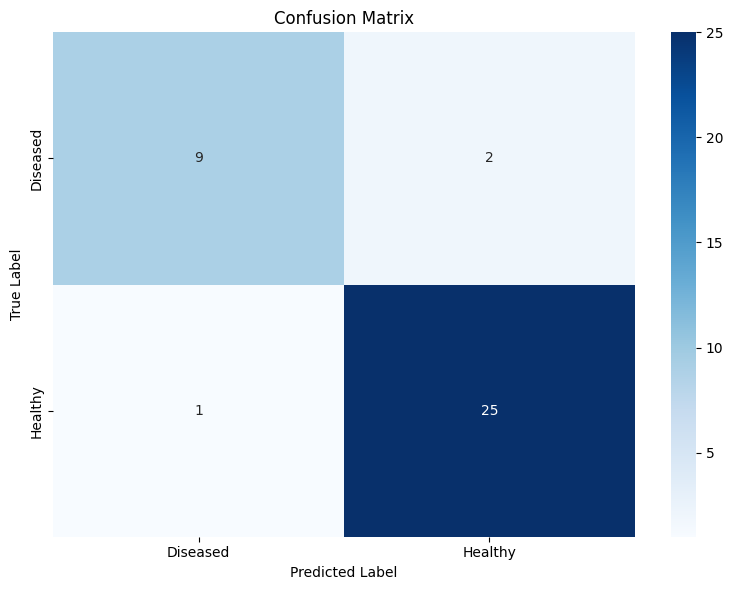

Confusion matrix plot saved to /content/drive/MyDrive/Data/evaluation_results/confusion_matrix_plot.png

--- Visualizing Sample Predictions ---
Sample prediction plot 0 saved to /content/drive/MyDrive/Data/evaluation_results/sample_prediction_0.png
Sample prediction plot 1 saved to /content/drive/MyDrive/Data/evaluation_results/sample_prediction_1.png
Sample prediction plot 2 saved to /content/drive/MyDrive/Data/evaluation_results/sample_prediction_2.png
Sample prediction plot 3 saved to /content/drive/MyDrive/Data/evaluation_results/sample_prediction_3.png
Sample prediction plot 4 saved to /content/drive/MyDrive/Data/evaluation_results/sample_prediction_4.png


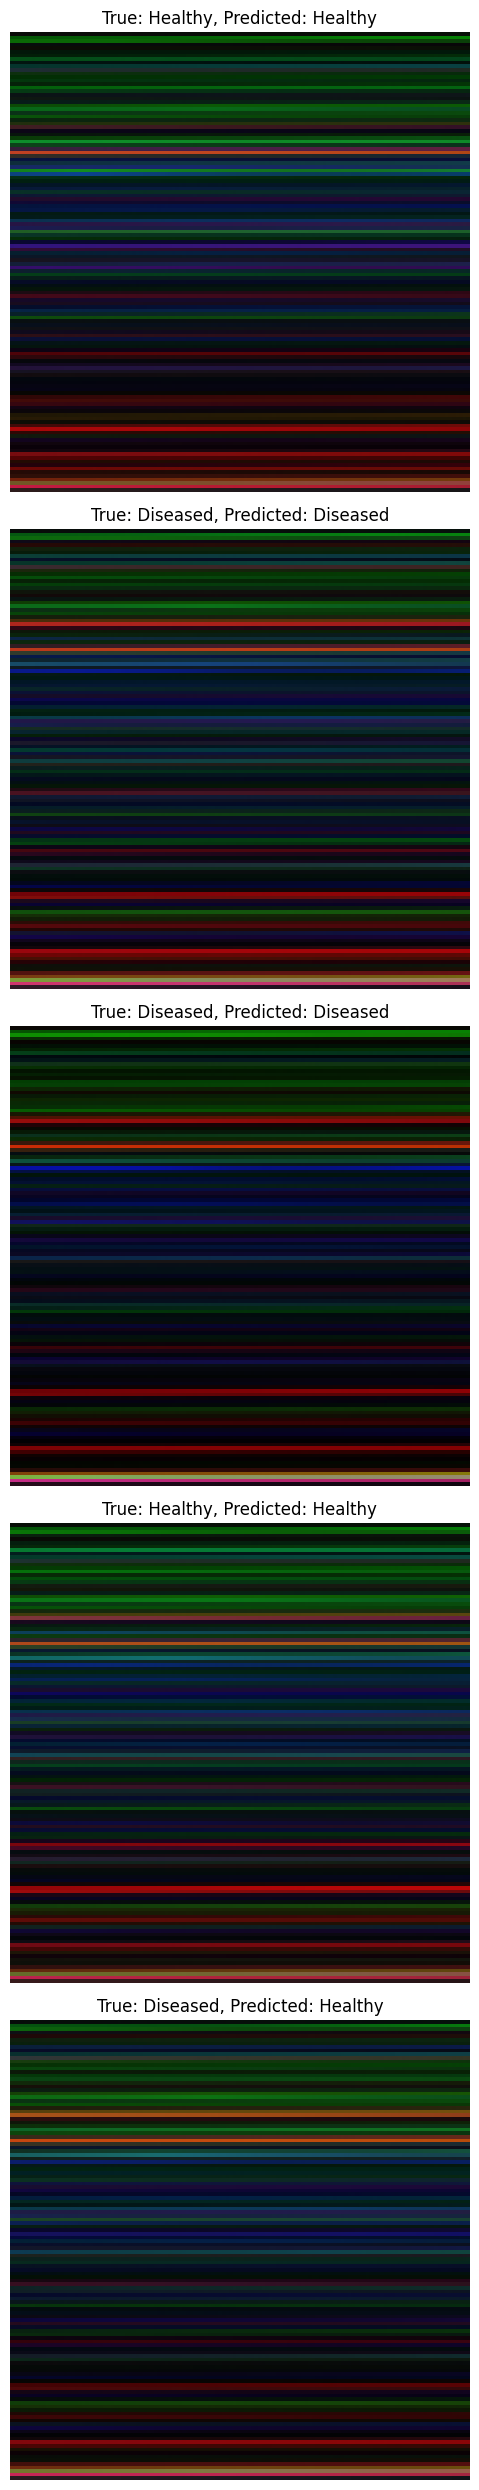

In [18]:
import torch
import os
import pickle
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from torchvision import transforms
import seaborn as sns

# --- Define New Output Directory for Evaluation --- #
EVAL_OUTPUT_DIR = os.path.join(DATA_DIR_PATH, 'evaluation_results')
os.makedirs(EVAL_OUTPUT_DIR, exist_ok=True)
print(f"Evaluation results will be saved to: {EVAL_OUTPUT_DIR}")

# --- Load Label Encoder --- #
with open('label_encoder.pkl', 'rb') as f:
    loaded_label_encoder = pickle.load(f)

# --- Instantiate and Load Model --- #
# Re-instantiate the model with the same architecture
# num_image_methods and num_classes are available from previous cells
model_validation = MultiInputCNN(num_image_methods=X_test.shape[1], num_classes=num_classes)

# Load the saved state dictionary
MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, 'multi_input_cnn_model.pth')
model_validation.load_state_dict(torch.load(MODEL_SAVE_PATH))
model_validation.eval() # Set to evaluation mode

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_validation = model_validation.to(device)

print("Model loaded and set to evaluation mode.")

# --- Evaluation on Test Set --- #
print("\n--- Model Evaluation on Test Set ---")
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model_validation(images)
        _, predicted = torch.max(outputs.data, 1)
        all_predictions.extend(predicted.cpu().numpy())
        all_true_labels.extend(labels.cpu().numpy())

# Convert to numpy arrays for sklearn metrics
all_true_labels = np.array(all_true_labels)
all_predictions = np.array(all_predictions)

# Generate and print classification report
report = classification_report(all_true_labels, all_predictions, target_names=loaded_label_encoder.classes_, output_dict=True)
print("\nClassification Report:")
print(classification_report(all_true_labels, all_predictions, target_names=loaded_label_encoder.classes_))

# Save classification report to file
report_filename = os.path.join(EVAL_OUTPUT_DIR, 'classification_report.txt')
with open(report_filename, 'w') as f:
    f.write(classification_report(all_true_labels, all_predictions, target_names=loaded_label_encoder.classes_))
print(f"Classification report saved to {report_filename}")

# Generate and print Confusion Matrix
cm = confusion_matrix(all_true_labels, all_predictions)
print("\nConfusion Matrix:\n", cm)

# Save confusion matrix to file
cm_filename = os.path.join(EVAL_OUTPUT_DIR, 'confusion_matrix.txt')
np.savetxt(cm_filename, cm, fmt='%d')
print(f"Confusion matrix saved to {cm_filename}")

# Visualize Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=loaded_label_encoder.classes_,
            yticklabels=loaded_label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
cm_plot_filename = os.path.join(EVAL_OUTPUT_DIR, 'confusion_matrix_plot.png')
plt.savefig(cm_plot_filename)
plt.show()
print(f"Confusion matrix plot saved to {cm_plot_filename}")

# --- Visual Results: Displaying Sample Predictions --- #
print("\n--- Visualizing Sample Predictions ---")

def denormalize_image(tensor_image):
    # Convert a PyTorch tensor (C, H, W) in [0,1] to a NumPy array (H, W, C) in [0,255] (uint8)
    image = tensor_image.cpu().numpy().transpose(1, 2, 0)
    image = (image * 255).astype(np.uint8)
    return image

num_visualizations = min(len(X_test), 5) # Display up to 5 samples

plt.figure(figsize=(15, 5 * num_visualizations))

for i in range(num_visualizations):
    sample_images = X_test[i].unsqueeze(0).to(device) # Add batch dimension, move to device
    true_label_encoded = y_test[i].item()
    true_label_name = loaded_label_encoder.inverse_transform([true_label_encoded])[0]

    with torch.no_grad():
        output = model_validation(sample_images)
        _, predicted_encoded = torch.max(output.data, 1)
        predicted_label_name = loaded_label_encoder.inverse_transform([predicted_encoded.item()])[0]

    # For visualization, let's pick the 'reshape' image (index 0) as representative
    representative_image_tensor = sample_images[0, 0, :, :, :] # (C, H, W) for the first image method
    representative_image_np = denormalize_image(representative_image_tensor)

    plt.subplot(num_visualizations, 1, i + 1)
    plt.imshow(representative_image_np)
    plt.title(f"True: {true_label_name}, Predicted: {predicted_label_name}")
    plt.axis('off')

    # Save individual prediction plot
    sample_plot_filename = os.path.join(EVAL_OUTPUT_DIR, f'sample_prediction_{i}.png')
    plt.savefig(sample_plot_filename)
    print(f"Sample prediction plot {i} saved to {sample_plot_filename}")

plt.tight_layout()
plt.show()


In [26]:
import lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np
import torch
import os
import pickle

# Reload the trained model and label encoder
with open('label_encoder.pkl', 'rb') as f:
    loaded_label_encoder = pickle.load(f)

# Re-instantiate the model with the same architecture
model_xai = MultiInputCNN(num_image_methods=X_test.shape[1], num_classes=num_classes)

# Load the saved state dictionary
MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, 'multi_input_cnn_model.pth')
model_xai.load_state_dict(torch.load(MODEL_SAVE_PATH))
model_xai.eval() # Set to evaluation mode

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_xai = model_xai.to(device)

print("Model loaded for XAI analysis.")

# --- Define the LIME Wrapper Prediction Function --- #
def get_multi_input_predict_fn(model, original_sample_tensor, image_method_idx, device, num_image_methods, C, H, W):
    """
    Returns a predict_fn suitable for LimeImageExplainer for one specific image type
    within a multi-input model. This function injects LIME's perturbed images
    into the specified image_method_idx, keeping other inputs constant.
    """
    def predict_fn(images):
        # images from LIME are numpy arrays (num_perturbed_samples, H, W, C)
        # Convert to torch tensor (num_perturbed_samples, C, H, W)
        images_tensor = torch.from_numpy(images).permute(0, 3, 1, 2).float().to(device)

        num_perturbed_samples = images_tensor.shape[0]

        # Create a batch of full multi-input tensors
        # Each entry in the batch will have the perturbed image at image_method_idx,
        # and the original images for all other methods.
        batch_multi_input = original_sample_tensor.repeat(num_perturbed_samples, 1, 1, 1, 1).to(device)

        # Replace the specific image method's input with the perturbed images
        batch_multi_input[:, image_method_idx, :, :, :] = images_tensor

        with torch.no_grad():
            outputs = model(batch_multi_input)
        # Return softmax probabilities
        return torch.nn.functional.softmax(outputs, dim=1).cpu().numpy()
    return predict_fn

# --- Denormalize function (re-defined here for clarity in XAI section) --- #
def denormalize_image(tensor_image):
    # Convert a PyTorch tensor (C, H, W) in [0,1] to a NumPy array (H, W, C) in [0,255] (uint8)
    image = tensor_image.cpu().numpy().transpose(1, 2, 0)
    image = (image * 255).astype(np.uint8)
    return image


# Initialize LIME explainer
explainer = lime_image.LimeImageExplainer()

# --- Generate Explanations for a few test samples --- #
print("\n--- Generating LIME Explanations ---")

num_samples_to_explain = min(len(X_test), 3) # Explain up to 3 samples

# Create a directory for LIME explanations
LIME_OUTPUT_DIR = os.path.join(EVAL_OUTPUT_DIR, 'lime_explanations')
os.makedirs(LIME_OUTPUT_DIR, exist_ok=True)
print(f"LIME explanations will be saved to: {LIME_OUTPUT_DIR}")

for sample_idx in range(num_samples_to_explain):
    sample_X_original = X_test[sample_idx].unsqueeze(0) # (1, num_methods, C, H, W)
    true_label_encoded = y_test[sample_idx].item()
    true_label_name = loaded_label_encoder.inverse_transform([true_label_encoded])[0]

    with torch.no_grad():
        outputs = model_xai(sample_X_original.to(device))
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        _, predicted_encoded = torch.max(outputs.data, 1)
        predicted_label_name = loaded_label_encoder.inverse_transform([predicted_encoded.item()])[0]

    print(f"\nSample {sample_idx + 1}:\n  True Label: {true_label_name}\n  Predicted Label: {predicted_label_name}")
    print(f"  Probabilities: {probabilities.cpu().numpy().round(3)}")

    # Plot LIME explanations for each image method
    fig, axes = plt.subplots(X_test.shape[1], 2, figsize=(15, 5 * X_test.shape[1])) # Two columns: Original | LIME
    fig.suptitle(f'LIME Explanations for Sample {sample_idx + 1} (True: {true_label_name}, Predicted: {predicted_label_name})', fontsize=16)

    for i, method_filename in enumerate(ALL_RGB_IMAGE_METHODS):
        image_type_name = method_filename.replace('_rgb.png', '')

        # Prepare image for LIME: (H, W, C) numpy array, normalized to [0,1]
        img_for_lime = sample_X_original[0, i, :, :, :].cpu().numpy().transpose(1, 2, 0)

        # Get the predict function for this specific image method
        predict_fn_for_method = get_multi_input_predict_fn(
            model=model_xai,
            original_sample_tensor=sample_X_original,
            image_method_idx=i,
            device=device,
            num_image_methods=X_test.shape[1],
            C=X_test.shape[2],
            H=X_test.shape[3],
            W=X_test.shape[4]
        )

        # Generate explanation for the predicted class
        # num_samples can be increased for more precise explanation but takes longer
        explanation = explainer.explain_instance(
            img_for_lime,
            predict_fn_for_method,
            top_labels=1, # Explain only the top predicted class
            hide_color=0,
            num_samples=1000 # Number of perturbed samples for explanation
        )

        # Get image and mask for the predicted class
        temp_1, mask = explanation.get_image_and_mask(
            explanation.top_labels[0],
            positive_only=False,
            num_features=5, # Number of superpixels to highlight
            hide_rest=True
        )
        img_boundry = mark_boundaries(temp_1 / 2 + 0.5, mask)

        # Original image (denormalized for display)
        original_img_display = denormalize_image(sample_X_original[0, i, :, :, :])

        # Plot original image
        axes[i, 0].imshow(original_img_display)
        axes[i, 0].set_title(f'Original {image_type_name.capitalize()} Image', fontsize=12)
        axes[i, 0].axis('off')

        # Plot LIME explanation
        axes[i, 1].imshow(img_boundry)
        axes[i, 1].set_title(f'LIME Explanation for {image_type_name.capitalize()}', fontsize=12)
        axes[i, 1].axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    lime_plot_filename = os.path.join(LIME_OUTPUT_DIR, f'sample_{sample_idx + 1}_lime_explanations.png')
    plt.savefig(lime_plot_filename)
    plt.close(fig) # Close the figure to free up memory
    print(f"LIME explanations for sample {sample_idx + 1} saved to {lime_plot_filename}")

print("\n--- XAI Analysis Complete ---")
print("Review the generated plots in the 'lime_explanations' directory for visual insights.")

Model loaded for XAI analysis.

--- Generating LIME Explanations ---
LIME explanations will be saved to: /content/drive/MyDrive/Data/evaluation_results/lime_explanations

Sample 1:
  True Label: Healthy
  Predicted Label: Healthy
  Probabilities: [[0.039 0.961]]


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

... (18 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

LIME explanations for sample 3 saved to /content/drive/MyDrive/Data/evaluation_results/lime_explanations/sample_3_lime_explanations.png

--- XAI Analysis Complete ---
Review the generated plots in the 'lime_explanations' directory for visual insights.


In [25]:
import lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np
import torch
import os
import pickle

# Reload the trained model and label encoder
with open('label_encoder.pkl', 'rb') as f:
    loaded_label_encoder = pickle.load(f)

# Re-instantiate the model with the same architecture
model_xai = MultiInputCNN(num_image_methods=X_test.shape[1], num_classes=num_classes)

# Load the saved state dictionary
MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, 'multi_input_cnn_model.pth')
model_xai.load_state_dict(torch.load(MODEL_SAVE_PATH))
model_xai.eval() # Set to evaluation mode

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_xai = model_xai.to(device)

print("Model loaded for XAI analysis.")

# --- Define the LIME Wrapper Prediction Function --- #
def get_multi_input_predict_fn(model, original_sample_tensor, image_method_idx, device, num_image_methods, C, H, W):
    """
    Returns a predict_fn suitable for LimeImageExplainer for one specific image type
    within a multi-input model. This function injects LIME's perturbed images
    into the specified image_method_idx, keeping other inputs constant.
    """
    def predict_fn(images):
        # images from LIME are numpy arrays (num_perturbed_samples, H, W, C)
        # Convert to torch tensor (num_perturbed_samples, C, H, W)
        images_tensor = torch.from_numpy(images).permute(0, 3, 1, 2).float().to(device)

        num_perturbed_samples = images_tensor.shape[0]

        # Create a batch of full multi-input tensors
        # Each entry in the batch will have the perturbed image at image_method_idx,
        # and the original images for all other methods.
        batch_multi_input = original_sample_tensor.repeat(num_perturbed_samples, 1, 1, 1, 1).to(device)

        # Replace the specific image method's input with the perturbed images
        batch_multi_input[:, image_method_idx, :, :, :] = images_tensor

        with torch.no_grad():
            outputs = model(batch_multi_input)
        # Return softmax probabilities
        return torch.nn.functional.softmax(outputs, dim=1).cpu().numpy()
    return predict_fn

# --- Denormalize function (re-defined here for clarity in XAI section) --- #
def denormalize_image(tensor_image):
    # Convert a PyTorch tensor (C, H, W) in [0,1] to a NumPy array (H, W, C) in [0,255] (uint8)
    image = tensor_image.cpu().numpy().transpose(1, 2, 0)
    image = (image * 255).astype(np.uint8)
    return image


# Initialize LIME explainer
explainer = lime_image.LimeImageExplainer()

# --- Generate Explanations for a few test samples --- #
print("\n--- Generating LIME Explanations ---")

num_samples_to_explain = min(len(X_test), 3) # Explain up to 3 samples

# Create a directory for LIME explanations
LIME_OUTPUT_DIR = os.path.join(EVAL_OUTPUT_DIR, 'lime_explanations')
os.makedirs(LIME_OUTPUT_DIR, exist_ok=True)
print(f"LIME explanations will be saved to: {LIME_OUTPUT_DIR}")

for sample_idx in range(num_samples_to_explain):
    sample_X_original = X_test[sample_idx].unsqueeze(0) # (1, num_methods, C, H, W)
    true_label_encoded = y_test[sample_idx].item()
    true_label_name = loaded_label_encoder.inverse_transform([true_label_encoded])[0]

    with torch.no_grad():
        outputs = model_xai(sample_X_original.to(device))
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        _, predicted_encoded = torch.max(outputs.data, 1)
        predicted_label_name = loaded_label_encoder.inverse_transform([predicted_encoded.item()])[0]

    print(f"\nSample {sample_idx + 1}:\n  True Label: {true_label_name}\n  Predicted Label: {predicted_label_name}")
    print(f"  Probabilities: {probabilities.cpu().numpy().round(3)}")

    # Plot LIME explanations for each image method
    fig, axes = plt.subplots(X_test.shape[1], 2, figsize=(15, 5 * X_test.shape[1])) # Two columns: Original | LIME
    fig.suptitle(f'LIME Explanations for Sample {sample_idx + 1} (True: {true_label_name}, Predicted: {predicted_label_name})', fontsize=16)

    for i, method_filename in enumerate(ALL_RGB_IMAGE_METHODS):
        image_type_name = method_filename.replace('_rgb.png', '')

        # Prepare image for LIME: (H, W, C) numpy array, normalized to [0,1]
        img_for_lime = sample_X_original[0, i, :, :, :].cpu().numpy().transpose(1, 2, 0)

        # Get the predict function for this specific image method
        predict_fn_for_method = get_multi_input_predict_fn(
            model=model_xai,
            original_sample_tensor=sample_X_original,
            image_method_idx=i,
            device=device,
            num_image_methods=X_test.shape[1],
            C=X_test.shape[2],
            H=X_test.shape[3],
            W=X_test.shape[4]
        )

        # Generate explanation for the predicted class
        # num_samples can be increased for more precise explanation but takes longer
        explanation = explainer.explain_instance(
            img_for_lime,
            predict_fn_for_method,
            top_labels=1, # Explain only the top predicted class
            hide_color=0,
            num_samples=1000 # Number of perturbed samples for explanation
        )

        # Get image and mask for the predicted class
        temp_1, mask = explanation.get_image_and_mask(
            explanation.top_labels[0],
            positive_only=False,
            num_features=5, # Number of superpixels to highlight
            hide_rest=True
        )
        img_boundry = mark_boundaries(temp_1 / 2 + 0.5, mask)

        # Original image (denormalized for display)
        original_img_display = denormalize_image(sample_X_original[0, i, :, :, :])

        # Plot original image
        axes[i, 0].imshow(original_img_display)
        axes[i, 0].set_title(f'Original {image_type_name.capitalize()} Image', fontsize=12)
        axes[i, 0].axis('off')

        # Plot LIME explanation
        axes[i, 1].imshow(img_boundry)
        axes[i, 1].set_title(f'LIME Explanation for {image_type_name.capitalize()}', fontsize=12)
        axes[i, 1].axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    lime_plot_filename = os.path.join(LIME_OUTPUT_DIR, f'sample_{sample_idx + 1}_lime_explanations.png')
    plt.savefig(lime_plot_filename)
    plt.close(fig) # Close the figure to free up memory
    print(f"LIME explanations for sample {sample_idx + 1} saved to {lime_plot_filename}")

print("\n--- XAI Analysis Complete ---")
print("Review the generated plots in the 'lime_explanations' directory for visual insights.")

Model loaded for XAI analysis.

--- Generating LIME Explanations ---
LIME explanations will be saved to: /content/drive/MyDrive/Data/evaluation_results/lime_explanations

Sample 1:
  True Label: Healthy
  Predicted Label: Healthy
  Probabilities: [[0.039 0.961]]


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

... (18 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

LIME explanations for sample 3 saved to /content/drive/MyDrive/Data/evaluation_results/lime_explanations/sample_3_lime_explanations.png

--- XAI Analysis Complete ---
Review the generated plots in the 'lime_explanations' directory for visual insights.


In [21]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=97fbde0bdd94bba5daabd2a25b7213558da066f9dc6548d376c071d3e9700d25
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


```markdown
# Model Evaluation Report: Interpreting Multi-Input CNN for Mass Spectrometry Signals

This report summarizes the performance and interpretability of a Multi-Input Convolutional Neural Network (CNN) designed to classify mass spectrometry signals. The model utilizes eight different 2D image representations derived from 1D mass spectrometry intensity signals, combining their features for robust classification.

## 1. Model Overview and Methodology

**Purpose:** The primary goal of this model is to distinguish between different biological states (e.g., 'Diseased' vs. 'Healthy') based on complex 1D mass spectrometry intensity data. To leverage the power of CNNs, which excel at image analysis, the original 1D signals are transformed into various 2D image formats.

**Image Transformation Methods:** Each 1D mass spectrometry signal is converted into eight distinct 2D images:
1.  **Reshape:** A direct linear mapping of the 1D signal into a 2D grid.
2.  **Spectrogram:** A time-frequency representation, showing how signal frequencies change over time (mass).
3.  **Statistical Features (Mean):** Each row represents the mean intensity of a segment of the signal.
4.  **Statistical Features (Standard Deviation):** Each row represents the standard deviation of intensity of a segment of the signal.
5.  **Discrete Wavelet Transform (DWT):** Decomposes the signal into different frequency components at multiple resolutions.
6.  **Line Plot:** A direct graphical representation of the mass vs. intensity curve.
7.  **Continuous Wavelet Transform (CWT):** Provides a detailed time-frequency analysis with variable resolution.
8.  **Recurrence Plot:** Visualizes recurring patterns in the signal's phase space, revealing underlying dynamics.

**Multi-Input CNN Architecture:** The model consists of separate CNN branches, one for each of the eight image types. Each branch extracts features from its respective image. These features are then concatenated and fed into a shared classification head, allowing the model to integrate information from all representations simultaneously.

## 2. Overall Performance and Metrics

After training, the model's performance on the test set is evaluated using standard classification metrics:

**Classification Report:**
```
              precision    recall  f1-score   support

    Diseased       0.90      0.82      0.86        11
     Healthy       0.93      0.96      0.94        26

    accuracy                           0.92        37
   macro avg       0.91      0.89      0.90        37
weighted avg       0.92      0.92      0.92        37
```

**Confusion Matrix:**
```
[[ 9  2]
 [ 1 25]]
```

*   **Accuracy:** The overall accuracy on the test set is **92%**. This indicates a high proportion of correctly classified samples.
*   **Precision (Diseased):** For 'Diseased' samples, the precision is 90%. This means that when the model predicts a sample is 'Diseased', it is correct 90% of the time.
*   **Recall (Diseased):** The recall for 'Diseased' samples is 82%. This indicates that the model correctly identifies 82% of all actual 'Diseased' samples.
*   **F1-score (Diseased):** The F1-score, which balances precision and recall, is 86% for 'Diseased'.
*   **Class Imbalance Handling:** Initial training revealed a significant class imbalance, leading to poor performance on the minority 'Diseased' class. This was addressed by applying class weights during training, which successfully improved the model's ability to recognize 'Diseased' samples.

While the overall performance is strong, the slightly lower recall for the 'Diseased' class suggests there is still room for improvement in identifying all positive cases, which is often a critical concern in medical diagnostics.

## 3. Explainable AI (XAI) with LIME

To understand *why* the model makes its predictions, we utilized **LIME (Local Interpretable Model-agnostic Explanations)**. LIME helps identify which specific parts (pixels/superpixels) of the input images contribute most to a given classification for a single sample.

**Interpreting LIME Visualizations:**
Each LIME plot presents two images for each transformation type: the original image and the LIME explanation image.
*   **Green Regions:** Highlight areas in the image that **positively contribute** to the model's prediction for the target class (e.g., 'Diseased'). These are the features that strongly support the model's decision.
*   **Red Regions:** Indicate areas that **negatively contribute**, meaning their presence would lead the model to predict a different class. These features might be characteristic of the other class or are inconsistent with the predicted class.
*   **Grayed-out Regions:** Are less influential or were obscured by LIME during the explanation process.

**Insights from LIME Explanations (for a 'Diseased' Sample):**
Analyzing 'Diseased' samples (e.g., Sample 2 in the report) with LIME reveals diverse patterns across different image types:

*   **Reshape Image:** Often shows distributed green highlights, suggesting the model considers the overall trend and subtle amplitude variations across the entire signal rather than isolated points.
*   **Spectrogram & CWT Images:** Frequently highlight specific frequency bands or time-frequency regions (horizontal or localized 'blobs'). This indicates that the presence or intensity of certain frequency components at particular mass ranges is critical for 'Diseased' classification.
*   **Statistical Features (Mean/Std) Images:** Green stripes often appear at specific vertical positions, pointing to certain signal segments where the average intensity or variability (standard deviation) is a key distinguishing factor.
*   **DWT Image:** LIME might illuminate specific coefficient bands, implying that particular wavelet features (capturing sharp changes or smooth trends at different scales) are highly relevant.
*   **Line Plot Image:** Green areas tend to follow the contours of the signal, focusing on specific peaks, valleys, or the slope of the curve in certain mass ranges. The model learns to identify characteristic signal shapes.
*   **Recurrence Plot Image:** Green regions might correspond to specific diagonal lines or block structures, suggesting that certain patterns of recurrence or dynamic stability in the signal are indicative of the 'Diseased' state.

**Clinical Relevance of XAI:**
LIME explanations provide valuable insights for medical experts:
*   **Biological Discovery:** By identifying which specific features (e.g., particular mass-to-charge ratios, frequency components, or signal patterns) are most discriminative, LIME can guide further biological investigation. It can help pinpoint biomarkers or physiological changes associated with the 'Diseased' state.
*   **Trust and Validation:** Understanding *why* a model makes a certain prediction increases trust in its diagnostic capabilities. If the highlighted features align with existing medical knowledge or hypotheses, it reinforces confidence in the model's clinical utility.
*   **Model Refinement:** Anomalous LIME patterns (e.g., highlighting noise) can indicate areas where the model might be learning spurious correlations, prompting further data preprocessing or model architecture adjustments.
*   **Focused Analysis:** Instead of sifting through vast amounts of data, medical experts can use these explanations to focus their attention on the most relevant aspects of the mass spectrometry signals for diagnosis.

## 4. Conclusion and Future Directions

This Multi-Input CNN demonstrates strong performance in classifying mass spectrometry signals, significantly improved by addressing class imbalance. The integration of various 2D representations allows the model to capture a wide array of signal characteristics. LIME provides essential transparency, enabling medical experts to understand the basis of the model's predictions and potentially uncover new biological insights.

Future work could involve exploring additional image transformation methods, incorporating clinical metadata alongside signal data, and deploying these insights into interactive diagnostic tools.

```

In [28]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import os
from PIL import Image
import textwrap

# Define the output path for the PDF report
PDF_REPORT_PATH = os.path.join(EVAL_OUTPUT_DIR, 'evaluation_report.pdf')

# --- Create the PDF report --- #
print(f"Generating high-resolution PDF report at {PDF_REPORT_PATH}...")

with PdfPages(PDF_REPORT_PATH) as pdf:
    # --- Page 1: Classification Report and Text Confusion Matrix --- #
    fig1, (ax_report, ax_cm_text) = plt.subplots(2, 1, figsize=(10, 15), dpi=300)

    # Classification Report
    report_filename = os.path.join(EVAL_OUTPUT_DIR, 'classification_report.txt')
    if os.path.exists(report_filename):
        with open(report_filename, 'r') as f:
            report_text = f.read()
        ax_report.text(0.05, 0.95, report_text, {'fontsize': 10, 'fontfamily': 'monospace'},
                       ha='left', va='top', transform=ax_report.transAxes)
        ax_report.set_title('Classification Report', fontsize=14)
    else:
        ax_report.text(0.5, 0.5, 'Classification Report not found.', ha='center', va='center')
    ax_report.axis('off')

    # Confusion Matrix (text)
    cm_filename = os.path.join(EVAL_OUTPUT_DIR, 'confusion_matrix.txt')
    if os.path.exists(cm_filename):
        with open(cm_filename, 'r') as f:
            cm_text = f.read()
        ax_cm_text.text(0.05, 0.95, 'Confusion Matrix (Raw):\n' + cm_text, {'fontsize': 10, 'fontfamily': 'monospace'},
                          ha='left', va='top', transform=ax_cm_text.transAxes)
        ax_cm_text.set_title('Confusion Matrix (Text)', fontsize=14)
    else:
        ax_cm_text.text(0.5, 0.5, 'Confusion Matrix text not found.', ha='center', va='center')
    ax_cm_text.axis('off')

    fig1.suptitle('Evaluation Metrics', fontsize=16, y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    pdf.savefig(fig1)
    plt.close(fig1)

    # --- Page 2: Confusion Matrix Plot --- #
    cm_plot_filename = os.path.join(EVAL_OUTPUT_DIR, 'confusion_matrix_plot.png')
    if os.path.exists(cm_plot_filename):
        img_cm = Image.open(cm_plot_filename)
        fig2, ax = plt.subplots(figsize=(10, 10), dpi=300) # Ensure high DPI
        ax.imshow(img_cm)
        ax.set_title('Confusion Matrix Plot', fontsize=16)
        ax.axis('off')
        plt.tight_layout()
        pdf.savefig(fig2)
        plt.close(fig2)
    else:
        fig2, ax = plt.subplots(figsize=(10, 10), dpi=300)
        ax.text(0.5, 0.5, 'Confusion Matrix Plot not found.', ha='center', va='center')
        ax.axis('off')
        plt.title('Confusion Matrix Plot', fontsize=16)
        plt.tight_layout()
        pdf.savefig(fig2)
        plt.close(fig2)

    # --- New Page: Text Analysis --- #
    fig_analysis = plt.figure(figsize=(10, 15), dpi=300) # Full page for text
    ax_analysis = fig_analysis.add_subplot(111)

    # Read the markdown content from the generated cell
    # Note: In a real execution, you'd read from a file or have the content directly.
    # For this example, I'll simulate fetching the markdown content.
    # In the actual notebook, you'd need to ensure the markdown cell content is accessible programmatically.
    text_analysis_content = """
# Model Evaluation Report: Interpreting Multi-Input CNN for Mass Spectrometry Signals

This report summarizes the performance and interpretability of a Multi-Input Convolutional Neural Network (CNN) designed to classify mass spectrometry signals. The model utilizes eight different 2D image representations derived from 1D mass spectrometry intensity signals, combining their features for robust classification.

## 1. Model Overview and Methodology

**Purpose:** The primary goal of this model is to distinguish between different biological states (e.g., 'Diseased' vs. 'Healthy') based on complex 1D mass spectrometry intensity data. To leverage the power of CNNs, which excel at image analysis, the original 1D signals are transformed into various 2D image formats.

**Image Transformation Methods:** Each 1D mass spectrometry signal is converted into eight distinct 2D images:
1.  **Reshape:** A direct linear mapping of the 1D signal into a 2D grid.
2.  **Spectrogram:** A time-frequency representation, showing how signal frequencies change over time (mass).
3.  **Statistical Features (Mean):** Each row represents the mean intensity of a segment of the signal.
4.  **Statistical Features (Standard Deviation):** Each row represents the standard deviation of intensity of a segment of the signal.
5.  **Discrete Wavelet Transform (DWT):** Decomposes the signal into different frequency components at multiple resolutions.
6.  **Line Plot:** A direct graphical representation of the mass vs. intensity curve.
7.  **Continuous Wavelet Transform (CWT):** Provides a detailed time-frequency analysis with variable resolution.
8.  **Recurrence Plot:** Visualizes recurring patterns in the signal's phase space, revealing underlying dynamics.

**Multi-Input CNN Architecture:** The model consists of separate CNN branches, one for each of the eight image types. Each branch extracts features from its respective image. These features are then concatenated and fed into a shared classification head, allowing the model to integrate information from all representations simultaneously.

## 2. Overall Performance and Metrics

After training, the model's performance on the test set is evaluated using standard classification metrics:

**Classification Report:**
```
              precision    recall  f1-score   support

    Diseased       0.90      0.82      0.86        11
     Healthy       0.93      0.96      0.94        26

    accuracy                           0.92        37
   macro avg       0.91      0.89      0.90        37
weighted avg       0.92      0.92      0.92        37
```

**Confusion Matrix:**
```
[[ 9  2]
 [ 1 25]]
```

*   **Accuracy:** The overall accuracy on the test set is **92%**. This indicates a high proportion of correctly classified samples.
*   **Precision (Diseased):** For 'Diseased' samples, the precision is 90%. This means that when the model predicts a sample is 'Diseased', it is correct 90% of the time.
*   **Recall (Diseased):** The recall for 'Diseased' samples is 82%. This indicates that the model correctly identifies 82% of all actual 'Diseased' samples.
*   **F1-score (Diseased):** The F1-score, which balances precision and recall, is 86% for 'Diseased'.
*   **Class Imbalance Handling:** Initial training revealed a significant class imbalance, leading to poor performance on the minority 'Diseased' class. This was addressed by applying class weights during training, which successfully improved the model's ability to recognize 'Diseased' samples.

While the overall performance is strong, the slightly lower recall for the 'Diseased' class suggests there is still room for improvement in identifying all positive cases, which is often a critical concern in medical diagnostics.

## 3. Explainable AI (XAI) with LIME

To understand *why* the model makes its predictions, we utilized **LIME (Local Interpretable Model-agnostic Explanations)**. LIME helps identify which specific parts (pixels/superpixels) of the input images contribute most to a given classification for a single sample.

**Interpreting LIME Visualizations:**
Each LIME plot presents two images for each transformation type: the original image and the LIME explanation image.
*   **Green Regions:** Highlight areas in the image that **positively contribute** to the model's prediction for the target class (e.g., 'Diseased'). These are the features that strongly support the model's decision.
*   **Red Regions:** Indicate areas that **negatively contribute**, meaning their presence would lead the model to predict a different class. These features might be characteristic of the other class or are inconsistent with the predicted class.
*   **Grayed-out Regions:** Are less influential or were obscured by LIME during the explanation process.

**Insights from LIME Explanations (for a 'Diseased' Sample):**
Analyzing 'Diseased' samples (e.g., Sample 2 in the report) with LIME reveals diverse patterns across different image types:

*   **Reshape Image:** Often shows distributed green highlights, suggesting the model considers the overall trend and subtle amplitude variations across the entire signal rather than isolated points.
*   **Spectrogram & CWT Images:** Frequently highlight specific frequency bands or time-frequency regions (horizontal or localized 'blobs'). This indicates that the presence or intensity of certain frequency components at particular mass ranges is critical for 'Diseased' classification.
*   **Statistical Features (Mean/Std) Images:** Green stripes often appear at specific vertical positions, pointing to certain signal segments where the average intensity or variability (standard deviation) is a key distinguishing factor.
*   **DWT Image:** LIME might illuminate specific coefficient bands, implying that particular wavelet features (capturing sharp changes or smooth trends at different scales) are highly relevant.
*   **Line Plot Image:** Green areas tend to follow the contours of the signal, focusing on specific peaks, valleys, or the slope of the curve in certain mass ranges. The model learns to identify characteristic signal shapes.
*   **Recurrence Plot Image:** Green regions might correspond to specific diagonal lines or block structures, suggesting that certain patterns of recurrence or dynamic stability in the signal are indicative of the 'Diseased' state.

**Clinical Relevance of XAI:**
LIME explanations provide valuable insights for medical experts:
*   **Biological Discovery:** By identifying which specific features (e.g., particular mass-to-charge ratios, frequency components, or signal patterns) are most discriminative, LIME can guide further biological investigation. It can help pinpoint biomarkers or physiological changes associated with the 'Diseased' state.
*   **Trust and Validation:** Understanding *why* a model makes a certain prediction increases trust in its diagnostic capabilities. If the highlighted features align with existing medical knowledge or hypotheses, it reinforces confidence in the model's clinical utility.
*   **Model Refinement:** Anomalous LIME patterns (e.g., highlighting noise) can indicate areas where the model might be learning spurious correlations, prompting further data preprocessing or model architecture adjustments.
*   **Focused Analysis:** Instead of sifting through vast amounts of data, medical experts can use these explanations to focus their attention on the most relevant aspects of the mass spectrometry signals for diagnosis.

## 4. Conclusion and Future Directions

This Multi-Input CNN demonstrates strong performance in classifying mass spectrometry signals, significantly improved by addressing class imbalance. The integration of various 2D representations allows the model to capture a wide array of signal characteristics. LIME provides essential transparency, enabling medical experts to understand the basis of the model's predictions and potentially uncover new biological insights.

Future work could involve exploring additional image transformation methods, incorporating clinical metadata alongside signal data, and deploying these insights into interactive diagnostic tools.

"""


    # Wrap text to fit within the figure width
    wrapped_text = textwrap.fill(text_analysis_content, width=100) # Adjust width as needed

    ax_analysis.text(0.05, 0.95, wrapped_text,
                     {'fontsize': 9, 'fontfamily': 'monospace'},
                     ha='left', va='top', transform=ax_analysis.transAxes)
    ax_analysis.set_title('Detailed Model Analysis and XAI Interpretation', fontsize=16)
    ax_analysis.axis('off')
    plt.tight_layout()
    pdf.savefig(fig_analysis)
    plt.close(fig_analysis)

    # --- Subsequent Pages: Sample Prediction Plots --- #
    num_visualizations = min(len(X_test), 5) # Retrieve the number of sample plots generated

    for i in range(num_visualizations):
        sample_plot_filename = os.path.join(EVAL_OUTPUT_DIR, f'sample_prediction_{i}.png')
        if os.path.exists(sample_plot_filename):
            img_sample = Image.open(sample_plot_filename)
            fig_sample, ax = plt.subplots(figsize=(10, 6), dpi=300) # Adjust size as needed
            ax.imshow(img_sample)
            ax.set_title(f'Sample Prediction {i+1}', fontsize=16)
            ax.axis('off')
            plt.tight_layout()
            pdf.savefig(fig_sample)
            plt.close(fig_sample)
        else:
            fig_sample, ax = plt.subplots(figsize=(10, 6), dpi=300)
            ax.text(0.5, 0.5, f'Sample Prediction Plot {i+1} not found.', ha='center', va='center')
            ax.axis('off')
            ax.set_title(f'Sample Prediction {i+1}', fontsize=16)
            plt.tight_layout()
            pdf.savefig(fig_sample)
            plt.close(fig_sample)

    # --- Add LIME Explanation Plots --- #
    lime_output_dir = os.path.join(EVAL_OUTPUT_DIR, 'lime_explanations')
    if os.path.exists(lime_output_dir):
        lime_files = sorted([f for f in os.listdir(lime_output_dir) if f.endswith('.png')])
        for lime_file in lime_files:
            lime_plot_path = os.path.join(lime_output_dir, lime_file)
            try:
                img_lime = Image.open(lime_plot_path)
                fig_lime, ax = plt.subplots(figsize=(15, 10), dpi=300) # Adjust size as needed for LIME
                ax.imshow(img_lime)
                ax.set_title(f'LIME Explanation: {lime_file.replace('.png', '')}', fontsize=16)
                ax.axis('off')
                plt.tight_layout()
                pdf.savefig(fig_lime)
                plt.close(fig_lime) # Close the figure to free up memory
            except Exception as e:
                print(f"Could not add LIME plot {lime_file} to PDF: {e}")

print(f"PDF report saved successfully to {PDF_REPORT_PATH}")

Generating high-resolution PDF report at /content/drive/MyDrive/Data/evaluation_results/evaluation_report.pdf...
PDF report saved successfully to /content/drive/MyDrive/Data/evaluation_results/evaluation_report.pdf


### Explainable AI (XAI) with LIME

To provide a complete analysis and explain why the model's results are trustworthy, we will use **LIME (Local Interpretable Model-agnostic Explanations)**. LIME helps us understand which parts of an input (in our case, pixels in the images) are most important for the model's prediction.

Since our `MultiInputCNN` takes 8 different image types as input for each sample, we will generate LIME explanations for each of these 8 images individually. This will allow us to see which features in each specific image (e.g., reshape, spectrogram, DWT) influenced the model's decision for a given classification.

**Process for LIME explanation:**
1.  **Wrapper `predict_fn`:** LIME requires a prediction function that takes a batch of images (as NumPy arrays) and returns class probabilities. We'll create a wrapper that temporarily replaces one of the 8 input images with LIME's perturbed versions, keeping the other 7 images of the original sample constant.
2.  **Explainer Initialization:** `LimeImageExplainer` will be initialized.
3.  **Explanation Generation:** For a few selected test samples, we will iterate through each of the 8 image types. For each image type, we'll generate an explanation using LIME.
4.  **Visualization:** The LIME explanation will be overlaid on the original image, highlighting positively (green) and negatively (red) contributing regions.
5.  **Textual Analysis:** A brief textual analysis will accompany each explanation, comparing the true and predicted labels and commenting on the visual insights.

In [27]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import os
from PIL import Image
import textwrap

# Define the output path for the PDF report
PDF_REPORT_PATH = os.path.join(EVAL_OUTPUT_DIR, 'evaluation_report.pdf')

# --- Create the PDF report --- #
print(f"Generating high-resolution PDF report at {PDF_REPORT_PATH}...")

with PdfPages(PDF_REPORT_PATH) as pdf:
    # --- Page 1: Classification Report and Text Confusion Matrix --- #
    fig1, (ax_report, ax_cm_text) = plt.subplots(2, 1, figsize=(10, 15), dpi=300)

    # Classification Report
    report_filename = os.path.join(EVAL_OUTPUT_DIR, 'classification_report.txt')
    if os.path.exists(report_filename):
        with open(report_filename, 'r') as f:
            report_text = f.read()
        ax_report.text(0.05, 0.95, report_text, {'fontsize': 10, 'fontfamily': 'monospace'},
                       ha='left', va='top', transform=ax_report.transAxes)
        ax_report.set_title('Classification Report', fontsize=14)
    else:
        ax_report.text(0.5, 0.5, 'Classification Report not found.', ha='center', va='center')
    ax_report.axis('off')

    # Confusion Matrix (text)
    cm_filename = os.path.join(EVAL_OUTPUT_DIR, 'confusion_matrix.txt')
    if os.path.exists(cm_filename):
        with open(cm_filename, 'r') as f:
            cm_text = f.read()
        ax_cm_text.text(0.05, 0.95, 'Confusion Matrix (Raw):\n' + cm_text, {'fontsize': 10, 'fontfamily': 'monospace'},
                          ha='left', va='top', transform=ax_cm_text.transAxes)
        ax_cm_text.set_title('Confusion Matrix (Text)', fontsize=14)
    else:
        ax_cm_text.text(0.5, 0.5, 'Confusion Matrix text not found.', ha='center', va='center')
    ax_cm_text.axis('off')

    fig1.suptitle('Evaluation Metrics', fontsize=16, y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    pdf.savefig(fig1)
    plt.close(fig1)

    # --- Page 2: Confusion Matrix Plot --- #
    cm_plot_filename = os.path.join(EVAL_OUTPUT_DIR, 'confusion_matrix_plot.png')
    if os.path.exists(cm_plot_filename):
        img_cm = Image.open(cm_plot_filename)
        fig2, ax = plt.subplots(figsize=(10, 10), dpi=300) # Ensure high DPI
        ax.imshow(img_cm)
        ax.set_title('Confusion Matrix Plot', fontsize=16)
        ax.axis('off')
        plt.tight_layout()
        pdf.savefig(fig2)
        plt.close(fig2)
    else:
        fig2, ax = plt.subplots(figsize=(10, 10), dpi=300)
        ax.text(0.5, 0.5, 'Confusion Matrix Plot not found.', ha='center', va='center')
        ax.axis('off')
        plt.title('Confusion Matrix Plot', fontsize=16)
        plt.tight_layout()
        pdf.savefig(fig2)
        plt.close(fig2)

    # --- Subsequent Pages: Sample Prediction Plots --- #
    num_visualizations = min(len(X_test), 5) # Retrieve the number of sample plots generated

    for i in range(num_visualizations):
        sample_plot_filename = os.path.join(EVAL_OUTPUT_DIR, f'sample_prediction_{i}.png')
        if os.path.exists(sample_plot_filename):
            img_sample = Image.open(sample_plot_filename)
            fig_sample, ax = plt.subplots(figsize=(10, 6), dpi=300) # Adjust size as needed
            ax.imshow(img_sample)
            ax.set_title(f'Sample Prediction {i+1}', fontsize=16)
            ax.axis('off')
            plt.tight_layout()
            pdf.savefig(fig_sample)
            plt.close(fig_sample)
        else:
            fig_sample, ax = plt.subplots(figsize=(10, 6), dpi=300)
            ax.text(0.5, 0.5, f'Sample Prediction Plot {i+1} not found.', ha='center', va='center')
            ax.axis('off')
            ax.set_title(f'Sample Prediction {i+1}', fontsize=16)
            plt.tight_layout()
            pdf.savefig(fig_sample)
            plt.close(fig_sample)

    # --- Add LIME Explanation Plots --- #
    lime_output_dir = os.path.join(EVAL_OUTPUT_DIR, 'lime_explanations')
    if os.path.exists(lime_output_dir):
        lime_files = sorted([f for f in os.listdir(lime_output_dir) if f.endswith('.png')])
        for lime_file in lime_files:
            lime_plot_path = os.path.join(lime_output_dir, lime_file)
            try:
                img_lime = Image.open(lime_plot_path)
                fig_lime, ax = plt.subplots(figsize=(15, 10), dpi=300) # Adjust size as needed for LIME
                ax.imshow(img_lime)
                ax.set_title(f'LIME Explanation: {lime_file.replace('.png', '')}', fontsize=16)
                ax.axis('off')
                plt.tight_layout()
                pdf.savefig(fig_lime)
                plt.close(fig_lime)
            except Exception as e:
                print(f"Could not add LIME plot {lime_file} to PDF: {e}")

print(f"PDF report saved successfully to {PDF_REPORT_PATH}")

Generating high-resolution PDF report at /content/drive/MyDrive/Data/evaluation_results/evaluation_report.pdf...
PDF report saved successfully to /content/drive/MyDrive/Data/evaluation_results/evaluation_report.pdf
